# Experiment 6 — Attention and Transformers

Experiment 5 showed two weaknesses of RNN classifiers. Squeezing a text into the **last hidden state** is a bottleneck, and a manipulative cue is **forgotten** after about 10 following words (vanishing gradients). Mean pooling helped, but it **dilutes** the cue when many other words are averaged in.
This experiment follows the lecture on **attention and Transformers** and replaces the fixed average with a **learned, weighted** one, then removes recurrence altogether.

| Lecture topic | Section |
|---|---|
| Recap: vanishing gradients; "more direct pass-through connections" as the fix | 6A, 6G |
| The bottleneck problem; mean pooling as the starting point; attention as a *weighted* average (query, keys, values) | 6A |
| General definition of attention: a query attends to values (here: cross-attention with one learned query) | 6A, 6B |
| Attention gives some interpretability: we can see what the model focuses on | 6A, 6F |
| Self-attention: $q_i = Qx_i,\ k_i = Kx_i,\ v_i = Vx_i$, $\alpha_{ij} = \operatorname{softmax}_j(q_i^\top k_j)$, $o_i = \sum_j \alpha_{ij} v_j$; the sequence-stacked matrix form | 6B |
| Barriers and solutions: no notion of order → **position representations** (sinusoidal, learned); no non-linearity → **feed-forward network**; looking at the future → **masking** | 6B, 6C, 6D, 6G |
| Multi-head attention and the **scaled** dot product | 6B, 6D |
| **Residual connections** and **layer normalization** ("Add & Norm"); the Transformer **encoder** block | 6C, 6D |
| The Transformer **decoder** (masked self-attention) as a language model | 6E |
| The quadratic cost of self-attention | 6G |

Machine translation itself is not part of our task (we have no parallel corpus), so the encoder–decoder model is not trained. Its key ingredient, attention from one sequence to another, is used in 6A: a learned query vector attends to the encoder's hidden states.

Everything is implemented **from scratch in NumPy**, as in Experiments 4–5, and every hand-written gradient is checked numerically (6C).

**Protocol.**
- Same data, shared `train_idx` / `test_idx` split (`src/data.py`), vocabulary (`<num>`, `<unk>`, 40 tokens) and GloVe-initialised embeddings as Experiment 5, so all test scores are comparable.
- Design choices (Transformer variant, number of LM epochs) are made on the same **validation split** as in Experiment 5: 20% of the training split, group-aware and stratified. Final models are retrained on the full training split with 3 seeds; the test set is used only for the final numbers.
- Classifiers use the optimizer settings of Experiments 4–5: SGD, learning rate 0.1, batch 32, 30 epochs, gradient clipping at norm 5. The Transformer language models use Adam (6E explains why).
- **One change for speed:** mini-batches group texts of similar length (shuffle, then sort within chunks of 8 batches). Randomly drawn batches are padded to about 33 tokens on average, while the average text has 7 tokens, so most of the computation would be spent on padding.

*Run notebooks 01–05 first: sections 6E and 6H read their results from `results/`.*

In [1]:
# 0. Make the shared `src` package importable (works from the repo root or from notebooks/)

import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

In [2]:
# Setup: imports, data, the shared split, and the same validation split as Experiment 5

import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

import gensim.downloader as api

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from src.data import RANDOM_STATE, load_all, load_table, save_table
from src.embeddings import tokenize_text

main_df, groups, real_df, external_synthetic_df, train_idx, test_idx = load_all()
HAS_EXTERNAL = len(real_df) > 0   # False when the original project dataset is not in data/
SEEDS = [0, 1, 2]                 # every neural model is trained with 3 seeds, as in Experiments 4-5

y_all = main_df["manipulative"].to_numpy()
y_train, y_test = y_all[train_idx], y_all[test_idx]

# validation split: first fold of a stratified + grouped 5-fold split of the training texts (as in Experiment 5)
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fit_pos, val_pos = next(inner.split(train_idx, y_train, groups[train_idx]))
fit_idx, val_idx = train_idx[fit_pos], train_idx[val_pos]

glove_model = api.load("glove-wiki-gigaword-100")
EMB_DIM = glove_model.vector_size

print("Training:", len(train_idx), "(fit", len(fit_idx), "+ validation", len(val_idx), ") | Test:", len(test_idx))

Training: 1879 (fit 1503 + validation 376 ) | Test: 470


## 6.0 Vocabulary and helpers (unchanged from Experiment 5)

The same tokens as in Experiment 5: `<s>`/`</s>` mark the start and end of a text, words seen once in training become `<unk>`, every number becomes `<num>`, and texts are cut after 40 tokens. The embedding matrix is initialised from GloVe and fine-tuned.

In [3]:
# 6.0 Vocabulary shared by all models (identical to Experiment 5) and small helpers

MAX_LEN = 40          # truncate texts after 40 tokens
MIN_COUNT = 2         # words seen once in training become <unk>
PAD, BOS, EOS, UNK, NUM = "<pad>", "<s>", "</s>", "<unk>", "<num>"


def lm_tokens(text):
    """Tokenize as in Experiments 3-5, map every number to <num>, truncate."""
    return [NUM if re.fullmatch(r"\d+(?:[.,]\d+)?", w) else w for w in tokenize_text(text)][:MAX_LEN]


train_token_counts = Counter(w for text in main_df["text"].iloc[train_idx] for w in lm_tokens(text))
itos = [PAD, BOS, EOS, UNK] + sorted(w for w, c in train_token_counts.items()
                                     if c >= MIN_COUNT and w not in (BOS, EOS, UNK))
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)


def encode(text):
    return [stoi.get(w, stoi[UNK]) for w in lm_tokens(text)]


seqs = [encode(t) for t in main_df["text"]]
S = lambda idx: [seqs[i] for i in idx]
real_seqs = [encode(t) for t in real_df["text"]]
synth_seqs = [encode(t) for t in external_synthetic_df["text"]]

# embedding matrix initialised from GloVe (special tokens and unknown words start at zero)
E_init = np.zeros((V, EMB_DIM))
for w, i in stoi.items():
    if w in glove_model:
        E_init[i] = glove_model[w]


def batchify(sequences, add_bos_eos=False):
    """Right-padded id matrix X and mask M. For a language model: inputs <s> x1..xT, targets x1..xT </s>."""
    inputs = [[stoi[BOS]] + s for s in sequences] if add_bos_eos else list(sequences)
    T = max(1, max(len(s) for s in inputs))
    X, M = np.zeros((len(inputs), T), dtype=int), np.zeros((len(inputs), T))
    for i, s in enumerate(inputs):
        X[i, :len(s)], M[i, :len(s)] = s, 1
    Y = None
    if add_bos_eos:
        Y = np.zeros_like(X)
        for i, s in enumerate(sequences):
            Y[i, :len(s) + 1] = s + [stoi[EOS]]
    return X, M, Y


def length_batches(sequences, batch_size, rng, chunk=8):
    """Shuffle, sort each chunk of `chunk` batches by length, and shuffle the batch order: less padding."""
    perm = rng.permutation(len(sequences))
    batches = []
    for start in range(0, len(perm), batch_size * chunk):
        part = sorted(perm[start:start + batch_size * chunk], key=lambda i: len(sequences[i]))
        batches += [np.array(part[i:i + batch_size]) for i in range(0, len(part), batch_size)]
    return [batches[i] for i in rng.permutation(len(batches))]


def softmax(Z):
    Z = Z - Z.max(axis=-1, keepdims=True)
    P = np.exp(Z)
    return P / P.sum(axis=-1, keepdims=True)


def clip_by_global_norm(grads, threshold):
    """Gradient clipping (Experiment 5): if ||g|| > threshold, rescale g to length `threshold`."""
    norm = np.sqrt(sum((g ** 2).sum() for g in grads.values()))
    if threshold is not None and norm > threshold:
        grads = {k: g * (threshold / norm) for k, g in grads.items()}
    return grads, norm


def binary_metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0), "F1": f1_score(y_true, y_pred, zero_division=0)}


lengths = np.array([len(s) for s in S(train_idx)])
rng_demo = np.random.RandomState(0)
random_pad = np.mean([lengths[rng_demo.permutation(len(lengths))[:32]].max() for _ in range(500)])
bucket_pad = np.mean([lengths[b].max() for b in length_batches(S(train_idx), 32, rng_demo)])
print("Vocabulary size |V|:", V)
print(f"Mean text length: {lengths.mean():.1f} tokens | padded batch length: random batches {random_pad:.1f}, "
      f"length-grouped batches {bucket_pad:.1f}")

Vocabulary size |V|: 1162
Mean text length: 7.0 tokens | padded batch length: random batches 31.1, length-grouped batches 10.3


## 6.1 A minimal layer framework

Experiments 4–5 wrote one forward and one backward function per model. A Transformer has many more pieces, so every piece becomes a small **module** with
- `params` (its weights) and `grads` (filled by `backward`),
- `forward(...)`, which caches what the backward pass needs,
- `backward(upstream gradient)`, which returns the gradient for its input: **[downstream gradient] = [upstream gradient] × [local gradient]**, as in Experiment 4B.

Modules can contain other modules. `named_params()` collects all weights as `"block0.attn.W_q"`, … so the optimizer and the gradient check can treat any model the same way.

In [4]:
# 6.1 Module base class and a linear layer

class Module:
    def __init__(self):
        self.params, self.grads, self.children = {}, {}, {}

    def named_params(self, prefix=""):
        out = {prefix + k: v for k, v in self.params.items()}
        for name, child in self.children.items():
            out.update(child.named_params(f"{prefix}{name}."))
        return out

    def named_grads(self, prefix=""):
        out = {prefix + k: v for k, v in self.grads.items()}
        for name, child in self.children.items():
            out.update(child.named_grads(f"{prefix}{name}."))
        return out


flat = lambda x: x.reshape(-1, x.shape[-1])      # (B, T, d) -> (B*T, d): every position is one row


class Linear(Module):
    """y = x W + b, applied to every position."""

    def __init__(self, d_in, d_out, rng):
        super().__init__()
        self.params = {"W": rng.randn(d_in, d_out) * np.sqrt(1.0 / d_in), "b": np.zeros(d_out)}

    def forward(self, x):
        self.x = x
        return x @ self.params["W"] + self.params["b"]

    def backward(self, dout):
        self.grads = {"W": flat(self.x).T @ flat(dout), "b": flat(dout).sum(axis=0)}
        return dout @ self.params["W"].T


print("Module framework defined.")

Module framework defined.


## Experiment 6A — From mean pooling to attention

The lecture starts from the RNN classifier of Experiment 5F: to get one sentence vector, take the **element-wise mean** of all hidden states. Attention replaces the fixed average with a **learned, weighted** one, a *soft lookup*: a **query** $q$ is compared with every **key** $k_t$, the scores become weights between 0 and 1, and the **values** $v_t$ are summed with these weights:
$$e_t = q^\top k_t, \qquad \alpha = \operatorname{softmax}(e), \qquad z = \sum_{t=1}^{T} \alpha_t\, v_t .$$

For classification we use the RNN hidden states as keys and values ($k_t = v_t = h^{(t)}$, as in seq2seq attention, where the decoder state attends to the encoder states) and a **learned query vector** $q$. This is the lecture's general definition: *given a set of values and a query, attention computes a weighted sum of the values that depends on the query*. It is also cross-attention with a single query that does not come from the input text.

| Pooling | Weights $\alpha_t$ | Path from word $t$ to the output |
|---|---|---|
| last state (5F) | 1 for $t = T$, else 0 | only through all later RNN steps → **bottleneck**, vanishing gradient |
| mean (5F) | $1/T$ for every word | direct, but every word counts equally → a cue is **diluted** in long texts |
| **attention** | learned, depend on the text | direct, and the model can **focus** on the cue |

Mean and last-state pooling are special cases of attention with fixed weights.

In [5]:
# 6A.1 Recurrent encoder (Experiment 5C, as a module), three poolings, and a generic sequence classifier

NEG_INF = -1e9    # score for positions that must get zero attention (padding, or the future in 6B-6E)


class RNNEncoder(Module):
    """h(t) = tanh(W_h h(t-1) + W_e e(t) + b), the same encoder and initialisation as Experiment 5C."""

    def __init__(self, rng, hidden=100):
        super().__init__()
        self.d = hidden
        self.params = {
            "E": E_init.copy(),
            "W_e": rng.randn(hidden, EMB_DIM) * np.sqrt(1.0 / EMB_DIM),
            "W_h": rng.randn(hidden, hidden) * np.sqrt(1.0 / hidden),
            "b": np.zeros(hidden),
        }

    def forward(self, X, M):
        P = self.params
        B, T = X.shape
        h = np.zeros((B, self.d))
        H, self.cache, self.X = np.zeros((B, T, self.d)), [], X
        for t in range(T):
            e = P["E"][X[:, t]]
            h_new = np.tanh(h @ P["W_h"].T + e @ P["W_e"].T + P["b"])
            m = M[:, t:t + 1]
            self.cache.append((h, e, h_new, m))
            h = m * h_new + (1 - m) * h                      # padding: keep the previous state
            H[:, t] = h
        return H

    def backward(self, dH):
        """Backpropagation through time (Experiment 5D). Also records ||dJ/dh(t)|| for 6A.4."""
        P, X = self.params, self.X
        g = {k: np.zeros_like(v) for k, v in P.items()}
        dh_next = np.zeros((X.shape[0], self.d))
        self.dh_norm = np.zeros(X.shape)
        for t in reversed(range(X.shape[1])):
            h_prev, e, h_new, m = self.cache[t]
            dh = dH[:, t] + dh_next
            self.dh_norm[:, t] = np.linalg.norm(dh, axis=1)
            da = dh * m * (1 - h_new ** 2)
            g["W_h"] += da.T @ h_prev
            g["W_e"] += da.T @ e
            g["b"] += da.sum(axis=0)
            np.add.at(g["E"], X[:, t], da @ P["W_e"])
            dh_next = da @ P["W_h"] + dh * (1 - m)
        self.grads = g


class LastPooling(Module):
    def forward(self, H, M):
        self.shape = H.shape
        return H[:, -1]                    # right padding copies the state, so the last column holds h(T)

    def backward(self, dz):
        dH = np.zeros(self.shape)
        dH[:, -1] = dz
        return dH


class MeanPooling(Module):
    def forward(self, H, M):
        self.w = M / np.maximum(M.sum(axis=1, keepdims=True), 1)
        return (self.w[..., None] * H).sum(axis=1)

    def backward(self, dz):
        return self.w[..., None] * dz[:, None, :]


class AttentionPooling(Module):
    """A learned query q attends to the states: e_t = q . h(t), alpha = softmax(e), z = sum_t alpha_t h(t)."""

    def __init__(self, d, rng):
        super().__init__()
        self.params = {"q": rng.randn(d) * np.sqrt(1.0 / d)}

    def forward(self, H, M):
        self.H = H
        # padding gets weight 0; "* (M > 0)" also gives an empty text (no tokens) z = 0, whatever the padding length
        self.alpha = softmax(np.where(M > 0, H @ self.params["q"], NEG_INF)) * (M > 0)
        return (self.alpha[..., None] * H).sum(axis=1)

    def backward(self, dz):
        d_alpha = (self.H * dz[:, None, :]).sum(axis=-1)                                  # dJ/d alpha_t = h(t) . dz
        de = self.alpha * (d_alpha - (d_alpha * self.alpha).sum(axis=-1, keepdims=True))    # back through softmax
        self.grads = {"q": np.einsum("bt,btd->d", de, self.H)}
        return self.alpha[..., None] * dz[:, None, :] + de[..., None] * self.params["q"]  # value path + key path


class SequenceClassifier(Module):
    """encoder -> pooling -> p = sigmoid(u . z + c), trained with binary cross-entropy (as in 5F)."""

    def __init__(self, encoder="rnn", pool="attention", seed=RANDOM_STATE, **encoder_options):
        super().__init__()
        self.rng = np.random.RandomState(seed)
        # TransformerEncoder is defined in 6C; the name is only looked up when a Transformer classifier is built
        enc = {"rnn": RNNEncoder, "transformer": lambda rng, **o: TransformerEncoder(rng, **o)}[encoder](
            self.rng, **encoder_options)
        self.params = {"u": self.rng.randn(enc.d) * np.sqrt(1.0 / enc.d), "c": np.zeros(1)}
        pooling = {"last": LastPooling, "mean": MeanPooling,
                   "attention": lambda: AttentionPooling(enc.d, self.rng)}[pool]()
        self.children = {"encoder": enc, "pool": pooling}

    def forward(self, X, M):
        z = self.children["pool"].forward(self.children["encoder"].forward(X, M), M)
        return z, 1 / (1 + np.exp(-(z @ self.params["u"] + self.params["c"][0])))

    def loss_and_grads(self, X, M, y):
        z, p = self.forward(X, M)
        loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
        ds = (p - y) / len(y)                                    # sigmoid + cross-entropy
        self.grads = {"u": z.T @ ds, "c": np.array([ds.sum()])}
        dH = self.children["pool"].backward(np.outer(ds, self.params["u"]))
        self.children["encoder"].backward(dH)
        return loss

    def fit(self, sequences, y, epochs=30, lr=0.1, batch_size=32, clip=5.0, val=None):
        params, self.history = self.named_params(), []
        for epoch in range(epochs):
            for idx in length_batches(sequences, batch_size, self.rng):
                X, M, _ = batchify([sequences[i] for i in idx])
                self.loss_and_grads(X, M, y[idx])
                grads = clip_by_global_norm(self.named_grads(), clip)[0]
                for k in params:
                    params[k] -= lr * grads[k]                   # SGD, as in Experiments 4-5
            if val is not None:
                self.history.append({"epoch": epoch + 1, "validation F1": f1_score(val[1], self.predict(val[0]))})
        self.train_loss = self.loss(sequences, y)
        return self

    def predict_proba(self, sequences, batch_size=256):
        """Batches of similar length (padding is masked, so the result does not depend on the batching)."""
        order, p = np.argsort([len(s) for s in sequences], kind="stable"), np.empty(len(sequences))
        for start in range(0, len(order), batch_size):
            idx = order[start:start + batch_size]
            p[idx] = self.forward(*batchify([sequences[i] for i in idx])[:2])[1]
        return p

    def predict(self, sequences):
        return (self.predict_proba(sequences) > 0.5).astype(int)

    def loss(self, sequences, y):
        p = self.predict_proba(sequences)
        return float(-np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)))

    def attention_weights(self, seq):
        """alpha over the words of one text (attention pooling only)."""
        self.forward(*batchify([seq])[:2])
        return self.children["pool"].alpha[0, :len(seq)]


print("RNN encoder, poolings and sequence classifier defined.")

RNN encoder, poolings and sequence classifier defined.


In [6]:
# 6A.2 RNN classifiers with last-state, mean and attention pooling (3 seeds each, full training split)

clf_models, clf_rows = {}, []
for pool in ["last", "mean", "attention"]:
    for seed in SEEDS:
        clf = SequenceClassifier("rnn", pool, seed=seed).fit(S(train_idx), y_train.astype(float))
        clf_models[(f"RNN + {pool}", seed)] = clf
        clf_rows.append({"Model": f"RNN + {pool}", "seed": seed, **binary_metrics(y_test, clf.predict(S(test_idx)))})

rnn_results = pd.DataFrame(clf_rows)
rnn_summary = rnn_results.groupby("Model", sort=False)[["Accuracy", "Precision", "Recall", "F1"]].mean()
rnn_summary["F1 std"] = rnn_results.groupby("Model", sort=False)["F1"].std()
display(rnn_summary.style.format("{:.3f}"))

,Accuracy,Precision,Recall,F1,F1 std
Model,,,,,
RNN + last,0.927,0.939,0.914,0.926,0.005
RNN + mean,0.949,0.955,0.944,0.949,0.009
RNN + attention,0.945,0.957,0.932,0.944,0.002


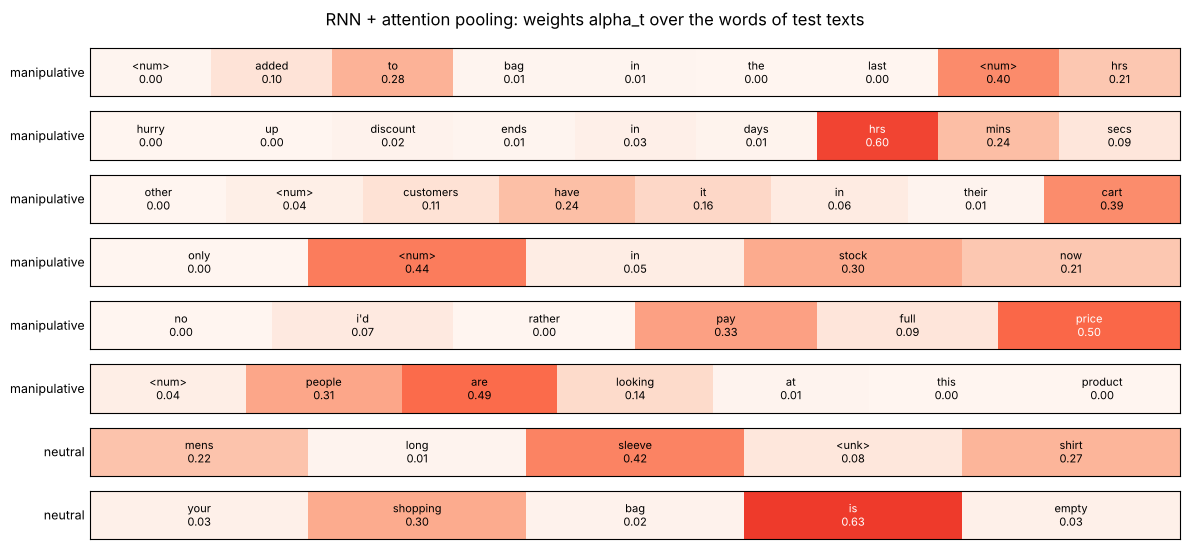

Highest mean attention, manipulative test texts: bought (0.58), purchased (0.58), don't (0.49), demand (0.43), i'd (0.32), hrs (0.30), <num> (0.30), viewed (0.30), added (0.29), pay (0.28), left (0.27), like (0.24)
Highest mean attention, neutral test texts:      products (0.35), <unk> (0.35), by (0.30), remotes (0.25), cookies (0.24), new (0.24), please (0.19), all (0.16), email (0.16), view (0.16), delivery (0.16), collection (0.14)


In [7]:
# 6A.3 Where does the attention-pooled RNN look? (seed 0, correctly classified test texts)

def show_attention(rows, title):
    """One row per text: every word coloured by its attention weight."""
    fig, axes = plt.subplots(len(rows), 1, figsize=(12, 0.62 * len(rows) + 0.6))
    for ax, (words, weights, label) in zip(np.atleast_1d(axes), rows):
        ax.imshow(np.array(weights)[None, :], cmap="Reds", vmin=0, vmax=1, aspect="auto")
        for j, (w, a) in enumerate(zip(words, weights)):
            ax.text(j, 0, f"{w}\n{a:.2f}", ha="center", va="center", fontsize=8, color="white" if a > 0.5 else "black")
        ax.set_xticks([]); ax.set_yticks([]); ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


rnn_attn = clf_models[("RNN + attention", 0)]
test_pred_rnn_attn = rnn_attn.predict(S(test_idx))
examples = list({tuple(seqs[i]): i for i, p in zip(test_idx, test_pred_rnn_attn)            # one text per token sequence
                 if p == y_all[i] and 5 <= len(seqs[i]) <= 12}.values())
rng_pick = np.random.RandomState(1)
example_ids = list(rng_pick.choice([i for i in examples if y_all[i] == 1], 6, replace=False)) + \
              list(rng_pick.choice([i for i in examples if y_all[i] == 0], 2, replace=False))
show_attention([([itos[w] for w in seqs[i]], rnn_attn.attention_weights(seqs[i]),
                 "manipulative" if y_all[i] else "neutral") for i in example_ids],
               "RNN + attention pooling: weights alpha_t over the words of test texts")


def most_attended(weights_fn, idx, min_count=5, top=12):
    """Average attention weight of every word type over the given texts (words seen >= min_count times)."""
    totals, counts = Counter(), Counter()
    for i in idx:
        for w, a in zip(seqs[i], weights_fn(seqs[i])):
            totals[itos[w]] += a
            counts[itos[w]] += 1
    mean_w = {w: totals[w] / counts[w] for w in counts if counts[w] >= min_count}
    return ", ".join(f"{w} ({a:.2f})" for w, a in sorted(mean_w.items(), key=lambda x: -x[1])[:top])


manip_test_idx, neutral_test_idx = test_idx[y_test == 1], test_idx[y_test == 0]
print("Highest mean attention, manipulative test texts:", most_attended(rnn_attn.attention_weights, manip_test_idx))
print("Highest mean attention, neutral test texts:     ", most_attended(rnn_attn.attention_weights, neutral_test_idx))

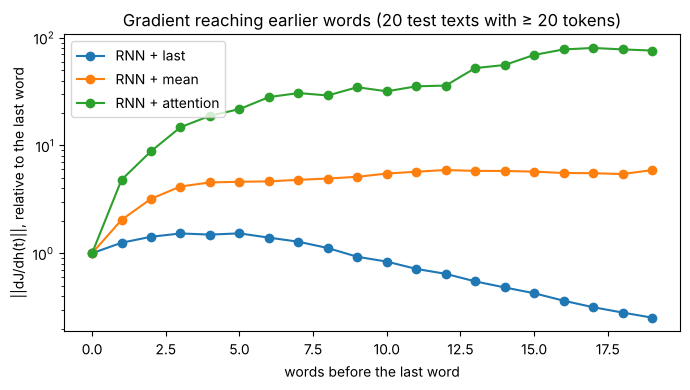

,RNN + last,RNN + mean,RNN + attention
5 words back,1.53,4.60,21.72
10 words back,0.84,5.48,31.76
19 words back,0.25,5.90,75.84


In [8]:
# 6A.4 Gradient reaching each word (as in 5G.2): ||dJ/dh(t)|| relative to the last word, test texts with >= 20 tokens

long_ids = [i for i in test_idx if len(seqs[i]) >= 20]
X_long, M_long, _ = batchify(S(long_ids))
long_lengths = M_long.sum(axis=1).astype(int)
K = 20
grad_profile = {}
for pool in ["last", "mean", "attention"]:
    clf = clf_models[(f"RNN + {pool}", 0)]
    clf.loss_and_grads(X_long, M_long, y_all[long_ids].astype(float))
    dh = clf.children["encoder"].dh_norm
    profile = np.array([[dh[i, n - 1 - k] / dh[i, n - 1] for k in range(K)] for i, n in enumerate(long_lengths)])
    grad_profile[f"RNN + {pool}"] = np.exp(np.log(profile + 1e-30).mean(axis=0))     # geometric mean over texts

plt.figure(figsize=(7, 4))
for name, profile in grad_profile.items():
    plt.plot(range(K), profile, marker="o", label=name)
plt.yscale("log"); plt.xlabel("words before the last word"); plt.ylabel("||dJ/dh(t)||, relative to the last word")
plt.title(f"Gradient reaching earlier words ({len(long_ids)} test texts with ≥ 20 tokens)")
plt.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame({name: {f"{k} words back": p[k] for k in (5, 10, 19)} for name, p in grad_profile.items()})
        .style.format("{:.2f}"))

## Experiment 6B — Self-attention, written from scratch

**Do we even need recurrence?** Attention already passes information from a sequence to a vector. *Self*-attention lets every word attend to every other word of the same text. With an embedding $x_i$ for word $i$ and weight matrices $Q, K, V \in \mathbb{R}^{d\times d}$:
$$q_i = Qx_i,\quad k_i = Kx_i,\quad v_i = Vx_i, \qquad e_{ij} = q_i^\top k_j, \qquad \alpha_{ij} = \frac{\exp(e_{ij})}{\sum_{j'}\exp(e_{ij'})}, \qquad o_i = \sum_j \alpha_{ij}\, v_j .$$
In matrix form, with the texts' word vectors stacked as rows of $X \in \mathbb{R}^{n\times d}$: $\;\text{output} = \operatorname{softmax}\big(XQ\,(XK)^\top\big)\,XV$.

**Multi-head attention** splits $Q, K, V$ into $h$ blocks of $d/h$ columns, runs attention in each head independently, concatenates the heads and mixes them with $Y \in \mathbb{R}^{d\times d}$. With the **scaled dot product**, scores are divided by $\sqrt{d/h}$:
$$\text{output}_\ell = \operatorname{softmax}\!\left(\frac{XQ_\ell\,K_\ell^\top X^\top}{\sqrt{d/h}}\right) XV_\ell, \qquad \text{output} = [\text{output}_1; \dots; \text{output}_h]\,Y .$$

`MultiHeadAttention` below takes queries from one input and keys/values from another, so the same code does **self-attention** (`x_q = x_kv`) and **cross-attention**. A key mask sets the scores of padding positions, and (for a decoder) of future positions, to $-\infty$.

In [9]:
# 6B.1 Multi-head scaled dot-product attention with masking

class MultiHeadAttention(Module):
    """Parameters named as in the lecture: Q, K, V (split into h heads of d/h columns) and the output mix Y."""

    def __init__(self, d, heads, rng, causal=False, scaled=True):
        super().__init__()
        self.params = {name: rng.randn(d, d) * np.sqrt(1.0 / d) for name in ["Q", "K", "V", "Y"]}
        self.heads, self.d_head, self.causal, self.scaled = heads, d // heads, causal, scaled

    def split_heads(self, x):    # (B, T, d) -> (B, h, T, d/h): the head axis becomes a batch axis
        B, T, _ = x.shape
        return x.reshape(B, T, self.heads, self.d_head).transpose(0, 2, 1, 3)

    def merge_heads(self, x):    # (B, h, T, d/h) -> (B, T, d): concatenate the heads
        B, _, T, _ = x.shape
        return x.transpose(0, 2, 1, 3).reshape(B, T, self.heads * self.d_head)

    def forward(self, x_q, x_kv, key_mask):
        P = self.params
        XQ, XK, XV = self.split_heads(x_q @ P["Q"]), self.split_heads(x_kv @ P["K"]), self.split_heads(x_kv @ P["V"])
        scale = 1 / np.sqrt(self.d_head) if self.scaled else 1.0
        scores = XQ @ XK.transpose(0, 1, 3, 2) * scale              # (B, h, T_q, T_kv): all pairs of attention scores
        allowed = key_mask[:, None, None, :] > 0                    # never attend to padding
        if self.causal:                                             # decoder: word i may only look at words j <= i
            allowed = allowed & np.tril(np.ones(scores.shape[-2:], dtype=bool))
        # attention distribution of every query; "* allowed" gives a query with no allowed key (empty text) output 0
        self.A = softmax(np.where(allowed, scores, NEG_INF)) * allowed
        O = self.merge_heads(self.A @ XV)
        self.cache = (x_q, x_kv, XQ, XK, XV, O, scale)
        return O @ P["Y"]

    def backward(self, dout):
        """Returns (dJ/dx_q, dJ/dx_kv); for self-attention the caller adds them."""
        P, A = self.params, self.A
        x_q, x_kv, XQ, XK, XV, O, scale = self.cache
        dO = self.split_heads(dout @ P["Y"].T)
        dA = dO @ XV.transpose(0, 1, 3, 2)
        dXV = A.transpose(0, 1, 3, 2) @ dO
        dS = A * (dA - (dA * A).sum(axis=-1, keepdims=True)) * scale    # softmax backward; masked entries have A = 0
        dXQ, dXK, dXV = self.merge_heads(dS @ XK), self.merge_heads(dS.transpose(0, 1, 3, 2) @ XQ), self.merge_heads(dXV)
        self.grads = {"Q": flat(x_q).T @ flat(dXQ), "K": flat(x_kv).T @ flat(dXK),
                      "V": flat(x_kv).T @ flat(dXV), "Y": flat(O).T @ flat(dout)}
        return dXQ @ P["Q"].T, dXK @ P["K"].T + dXV @ P["V"].T


def sinusoidal_positions(n, d):
    """p_i = (sin(i / 10000^(2j/d)), cos(i / 10000^(2j/d)))_j for positions i = 0..n-1."""
    angles = np.arange(n)[:, None] / 10000 ** (2 * np.arange(d // 2)[None, :] / d)
    P = np.zeros((n, d))
    P[:, 0::2], P[:, 1::2] = np.sin(angles), np.cos(angles)
    return P


print("Multi-head attention defined.")

Multi-head attention defined.


### 6B.2 Checking the lecture's statements numerically

Each row tests one statement from the lecture on the text *"only &lt;num&gt; left in stock"* (GloVe vectors, random weights). A difference of about $10^{-15}$ means *equal up to floating-point error*.

In [10]:
# 6B.2 Self-attention: equations, multi-head reshaping, order, masking, and stacking without non-linearities

rng_sa = np.random.RandomState(0)
words = ["only", NUM, "left", "in", "stock"]
X1 = E_init[[stoi[w] for w in words]][None]          # (1, n, d): one text
mask1 = np.ones((1, len(words)))
x, n, d = X1[0], len(words), EMB_DIM
checks = []

# (1) the per-word equations vs. the sequence-stacked form softmax(XQ (XK)^T) XV (one head, no scaling)
att1 = MultiHeadAttention(d, heads=1, rng=rng_sa, scaled=False)
Qm, Km, Vm, Ym = (att1.params[k] for k in "QKVY")
o = []
for i in range(n):
    e_i = np.array([(x[i] @ Qm) @ (x[j] @ Km) for j in range(n)])          # e_ij = q_i . k_j
    alpha_i = np.exp(e_i - e_i.max()) / np.exp(e_i - e_i.max()).sum()       # softmax over j
    o.append(sum(alpha_i[j] * (x[j] @ Vm) for j in range(n)))               # o_i = sum_j alpha_ij v_j
checks.append(("per-word equations = sequence-stacked matrix form",
               np.abs(np.array(o) @ Ym - att1.forward(X1, X1, mask1)[0]).max()))

# (2) multi-head attention = h separate attentions on d/h-column slices of Q, K, V, concatenated, then Y
mha = MultiHeadAttention(d, heads=4, rng=rng_sa)
dh = d // 4
heads_out = [softmax((x @ mha.params["Q"][:, l * dh:(l + 1) * dh]) @ (x @ mha.params["K"][:, l * dh:(l + 1) * dh]).T
                     / np.sqrt(dh)) @ (x @ mha.params["V"][:, l * dh:(l + 1) * dh]) for l in range(4)]
out = mha.forward(X1, X1, mask1)[0]
checks.append(("multi-head (reshape to h x n x d/h) = 4 separate heads, concatenated",
               np.abs(np.concatenate(heads_out, axis=1) @ mha.params["Y"] - out).max()))

# (3) no notion of order: permuting the words only permutes the outputs ...
perm = np.array([2, 0, 4, 1, 3])
checks.append(("no positions: permuting the words permutes the outputs (should be 0)",
               np.abs(out[perm] - mha.forward(X1[:, perm], X1[:, perm], mask1)[0]).max()))
# ... unless position vectors are added to the inputs
pos = sinusoidal_positions(n, d)
out_pos = mha.forward(X1 + pos, X1 + pos, mask1)[0]
out_pos_perm = mha.forward(X1[:, perm] + pos, X1[:, perm] + pos, mask1)[0]
checks.append(("with sinusoidal positions added (should be > 0)", np.abs(out_pos[perm] - out_pos_perm).max()))

# (4) masking the future: changing the last two words leaves the outputs of the first three unchanged
causal = MultiHeadAttention(d, heads=4, rng=rng_sa, causal=True)
X2 = X1.copy()
X2[0, 3:] = E_init[[stoi["now"], stoi["hurry"]]]
o1, o2 = causal.forward(X1, X1, mask1)[0], causal.forward(X2, X2, mask1)[0]
checks.append(("causal mask: outputs before the changed words (should be 0)", np.abs(o1[:3] - o2[:3]).max()))
checks.append(("causal mask: outputs at the changed words (should be > 0)", np.abs(o1[3:] - o2[3:]).max()))

# (5) no non-linearity: two attention layers = ONE weighted average of the inputs, times ONE matrix
a1, a2 = MultiHeadAttention(d, 1, rng_sa), MultiHeadAttention(d, 1, rng_sa)
h1 = a1.forward(X1, X1, mask1)
h2 = a2.forward(h1, h1, mask1)[0]
weights = a2.A[0, 0] @ a1.A[0, 0]                                 # rows still sum to 1
W_total = a1.params["V"] @ a1.params["Y"] @ a2.params["V"] @ a2.params["Y"]
checks.append(("2 attention layers without FFN = (A2 A1) X W  (re-averaged values)", np.abs(weights @ x @ W_total - h2).max()))

display(pd.DataFrame(checks, columns=["statement", "max |difference|"]).style.format({"max |difference|": "{:.1e}"})
        .hide(axis="index"))
print("Parameters of multi-head attention, 1 head vs. 4 heads:",
      sum(v.size for v in att1.params.values()), "vs.", sum(v.size for v in mha.params.values()))

statement,max |difference|
per-word equations = sequence-stacked matrix form,8.9e-16
"multi-head (reshape to h x n x d/h) = 4 separate heads, concatenated",3.3e-16
no positions: permuting the words permutes the outputs (should be 0),4.4e-16
with sinusoidal positions added (should be > 0),1.9e-01
causal mask: outputs before the changed words (should be 0),0.0e+00
causal mask: outputs at the changed words (should be > 0),6.1e-01
2 attention layers without FFN = (A2 A1) X W (re-averaged values),1.1e-15


Parameters of multi-head attention, 1 head vs. 4 heads: 40000 vs. 40000


### 6B.3 Why the dot product is scaled

The lecture's argument: for random $q, k \in \mathbb{R}^{d}$ with unit-variance entries, $q^\top k$ has variance $d$, so scores grow with the dimension, the softmax becomes almost one-hot, and its gradient becomes small. We measure this directly for 20 keys and a random upstream gradient $\partial J/\partial\alpha$.

In [11]:
# 6B.3 Size of the scores, peakedness of the softmax, and the gradient that passes through it

rng_scale = np.random.RandomState(0)
scale_rows = []
for d_k in [4, 16, 64, 256, 1024]:
    q, k, g = rng_scale.randn(2000, 1, d_k), rng_scale.randn(2000, 20, d_k), rng_scale.randn(2000, 20)
    for scaled in [False, True]:
        e = (q * k).sum(axis=-1) / (np.sqrt(d_k) if scaled else 1.0)
        a = softmax(e)
        de = a * (g - (g * a).sum(axis=-1, keepdims=True))          # dJ/de through the softmax
        scale_rows.append({"d_k": d_k, "scores": "q.k / sqrt(d_k)" if scaled else "q.k",
                           "std of scores": e.std(), "mean largest weight": a.max(axis=-1).mean(),
                           "mean ||dJ/de||": np.linalg.norm(de, axis=-1).mean()})
scale_table = pd.DataFrame(scale_rows).pivot(index="d_k", columns="scores")
display(scale_table.style.format("{:.3g}"))

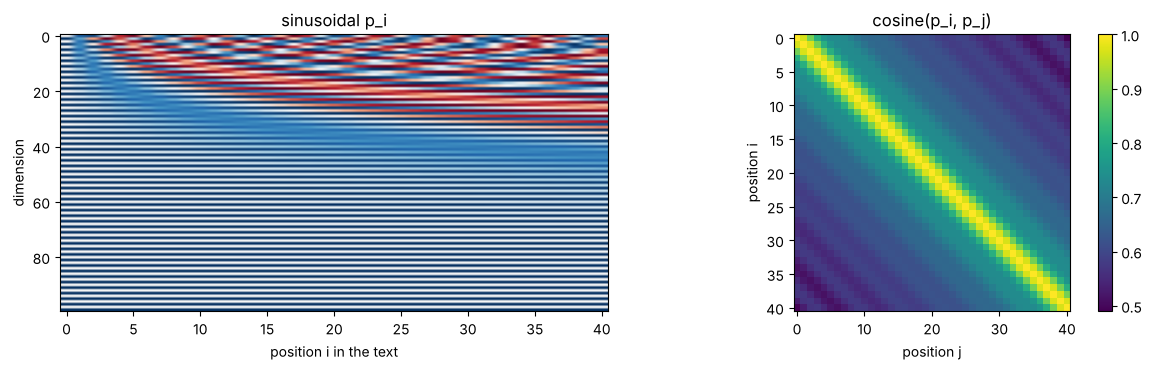

Norm of a position vector: 7.07 | median norm of a GloVe word vector: 5.55


In [12]:
# 6B.4 Sinusoidal position representations (lecture figure) and how similar two positions are

P_sin = sinusoidal_positions(MAX_LEN + 1, EMB_DIM)
unit = P_sin / np.linalg.norm(P_sin, axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].imshow(P_sin.T, aspect="auto", cmap="RdBu")
axes[0].set_xlabel("position i in the text"); axes[0].set_ylabel("dimension"); axes[0].set_title("sinusoidal p_i")
im = axes[1].imshow(unit @ unit.T, cmap="viridis")
axes[1].set_xlabel("position j"); axes[1].set_ylabel("position i"); axes[1].set_title("cosine(p_i, p_j)")
plt.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()
print(f"Norm of a position vector: {np.linalg.norm(P_sin[0]):.2f} | median norm of a GloVe word vector: "
      f"{np.median(np.linalg.norm(E_init[np.abs(E_init).sum(1) > 0], axis=1)):.2f}")

**Reading 6B.**
- **The lecture's equations hold exactly.** The per-word equations and the sequence-stacked form $\operatorname{softmax}(XQ(XK)^\top)XV$ agree to $10^{-15}$. Multi-head attention is the same as running 4 separate attentions on 25-column slices of $Q, K, V$ and concatenating them, and it has exactly as many parameters as one head (40,000): "not really more costly".
- **Barrier 1, no notion of order.** Without position vectors, permuting the words only permutes the outputs (difference $4\times10^{-16}$), so any pooled representation is identical for every word order: self-attention alone is a bag of words. Adding sinusoidal position vectors breaks this (0.19).
- **Barrier 3, looking at the future.** With the causal mask, changing the last two words leaves the outputs of the first three words exactly unchanged (difference 0), while the outputs at the changed positions differ (0.61).
- **Barrier 2, no non-linearity.** Two stacked attention layers without a feed-forward network are exactly one weighted average of the inputs times one matrix, $(A_2A_1)\,X\,W$: stacking only re-averages value vectors.
- **Scaling (6B.3).** Without scaling, the spread of the scores grows like $\sqrt{d_k}$ (std 2.0 for $d_k=4$, 31.9 for $d_k=1024$), the softmax becomes almost one-hot (mean largest weight 0.39 → 0.95), and the gradient passing through it shrinks almost 6× (0.29 → 0.05). Dividing by $\sqrt{d_k}$ keeps all three constant for every $d_k$ (std ≈ 1, largest weight ≈ 0.21, gradient ≈ 0.27).
- **Sinusoidal positions (6B.4).** The cosine between two position vectors depends only on their distance $|i-j|$ (the diagonal bands) and falls with it, so the vectors encode *relative* position. Their norm (7.1) is larger than that of a typical GloVe vector (5.6), so position is a strong part of every input vector.

## Experiment 6C — The Transformer block, and checking every gradient

The lecture adds three components to make self-attention a building block, giving the Transformer **encoder** block:

| Barrier | Solution | Here |
|---|---|---|
| no notion of order | add position vectors to the inputs: $\tilde x_i = x_i + p_i$ (sinusoidal or learned) | `TransformerEncoder` |
| no non-linearity, "just weighted averages" | a feed-forward network on every position: $m_i = W_2\,\mathrm{ReLU}(W_1 o_i + b_1) + b_2$ | `FeedForward` |
| training a deep stack | **residual connections** $x + \mathrm{Layer}(x)$ (the gradient through the "+" is 1) and **layer normalization** $\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}\,\gamma + \beta$ | `TransformerBlock` ("Add & Norm") |

Block: $x \to \mathrm{LayerNorm}(x + \mathrm{MultiHeadAttention}(x)) \to \mathrm{LayerNorm}(\,\cdot + \mathrm{FFN}(\cdot))$, as in the lecture's diagram. The **decoder** block is the same with the causal mask switched on (6E).
Each component can be switched off for the ablations in 6D.

In [13]:
# 6C.1 Layer normalization, feed-forward network, Transformer block and encoder

class LayerNorm(Module):
    """Normalise every vector to mean 0 / variance 1, then rescale with learned gain gamma and bias beta."""

    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.params, self.eps = {"gamma": np.ones(d), "beta": np.zeros(d)}, eps

    def forward(self, x):
        self.inv_std = 1 / np.sqrt(x.var(axis=-1, keepdims=True) + self.eps)
        self.x_hat = (x - x.mean(axis=-1, keepdims=True)) * self.inv_std
        return self.x_hat * self.params["gamma"] + self.params["beta"]

    def backward(self, dout):
        self.grads = {"gamma": flat(dout * self.x_hat).sum(axis=0), "beta": flat(dout).sum(axis=0)}
        dx_hat = dout * self.params["gamma"]
        return self.inv_std * (dx_hat - dx_hat.mean(axis=-1, keepdims=True)
                               - self.x_hat * (dx_hat * self.x_hat).mean(axis=-1, keepdims=True))


class FeedForward(Module):
    """m = W2 ReLU(W1 x + b1) + b2, the same network applied to every position."""

    def __init__(self, d, d_ff, rng):
        super().__init__()
        self.children = {"lin1": Linear(d, d_ff, rng), "lin2": Linear(d_ff, d, rng)}

    def forward(self, x):
        self.z = self.children["lin1"].forward(x)
        return self.children["lin2"].forward(np.maximum(self.z, 0))

    def backward(self, dout):
        return self.children["lin1"].backward(self.children["lin2"].backward(dout) * (self.z > 0))


class TransformerBlock(Module):
    """x -> Add & Norm(x, MultiHeadAttention(x)) -> Add & Norm(., FeedForward(.)); parts can be switched off."""

    def __init__(self, d, heads, d_ff, rng, causal=False, scaled=True, ffn=True, residual=True, layer_norm=True):
        super().__init__()
        self.children["attn"] = MultiHeadAttention(d, heads, rng, causal, scaled)
        if layer_norm:
            self.children["norm1"] = LayerNorm(d)
        if ffn:
            self.children["ffn"] = FeedForward(d, d_ff, rng)
            if layer_norm:
                self.children["norm2"] = LayerNorm(d)
        self.residual = residual

    def add_norm(self, x, sublayer_out, norm):
        y = x + sublayer_out if self.residual else sublayer_out
        return self.children[norm].forward(y) if norm in self.children else y

    def add_norm_backward(self, dout, norm):
        return self.children[norm].backward(dout) if norm in self.children else dout

    def forward(self, x, mask):
        x = self.add_norm(x, self.children["attn"].forward(x, x, mask), "norm1")
        if "ffn" in self.children:
            x = self.add_norm(x, self.children["ffn"].forward(x), "norm2")
        return x

    def backward(self, dout):
        if "ffn" in self.children:
            dy = self.add_norm_backward(dout, "norm2")
            dout = self.children["ffn"].backward(dy) + (dy if self.residual else 0)   # residual: gradient passes as is
        dy = self.add_norm_backward(dout, "norm1")
        dx_q, dx_kv = self.children["attn"].backward(dy)
        return dx_q + dx_kv + (dy if self.residual else 0)


class TransformerEncoder(Module):
    """Embeddings + position representations, then a stack of Transformer blocks (causal=True: decoder)."""

    def __init__(self, rng, layers=1, heads=4, d_ff=200, positions="sinusoidal", **block_options):
        super().__init__()
        self.d, self.positions = EMB_DIM, positions
        self.params["E"] = E_init.copy()
        if positions == "learned":                                # one learned vector per position 0..MAX_LEN
            self.params["P"] = rng.randn(MAX_LEN + 1, self.d) * 0.1
        for l in range(layers):
            self.children[f"block{l}"] = TransformerBlock(self.d, heads, d_ff, rng, **block_options)

    def forward(self, X, M):
        self.X = X
        T = X.shape[1]
        x = self.params["E"][X]
        if self.positions == "sinusoidal":
            x = x + sinusoidal_positions(T, self.d)                # defined for any length
        elif self.positions == "learned":
            if T > len(self.params["P"]):
                raise ValueError(f"learned positions exist only for {len(self.params['P'])} positions, got {T}")
            x = x + self.params["P"][:T]
        for block in self.children.values():
            x = block.forward(x, M)
        return x

    def backward(self, dH):
        self.grad_norms = []                                     # ||dJ/dx|| at the input of every block (6C.3)
        for block in reversed(list(self.children.values())):
            dH = block.backward(dH)
            self.grad_norms.append(np.linalg.norm(dH))
        gE = np.zeros_like(self.params["E"])
        np.add.at(gE, self.X, dH)
        self.grads = {"E": gE}
        if self.positions == "learned":
            gP = np.zeros_like(self.params["P"])
            gP[:dH.shape[1]] = dH.sum(axis=0)
            self.grads["P"] = gP


print("Transformer encoder defined.")

Transformer encoder defined.


### 6C.2 Gradient check

As in Experiments 4D and 5D, every analytic gradient is compared with the numerical estimate $\frac{J(\theta+\epsilon)-J(\theta-\epsilon)}{2\epsilon}$ on a small batch, for every parameter of every model in this experiment (parameters of the same kind, e.g. $Q$ in different blocks, are shown in one column). The Transformer language model is checked in 6E.

In [14]:
# 6C.2 Numerical gradient check for all parameters

def relative_error(a, b):
    return np.abs(a - b) / np.maximum(1e-8, np.abs(a) + np.abs(b))


def param_kind(name):
    """'encoder.block1.ffn.lin2.W' -> 'FFN W2', 'encoder.block0.attn.Q' -> 'attention Q', ..."""
    *path, leaf = name.split(".")
    if "ffn" in path:
        return f"FFN {leaf}{path[-1][-1]}"
    if leaf in ("gamma", "beta"):
        return f"LayerNorm {leaf}"
    if path and path[-1] == "attn":
        return f"attention {leaf}"
    return {"q": "pooling query q", "P": "learned positions P", "U": "LM output U", "b2": "LM output b2"}.get(leaf, leaf)


def gradient_check(model, loss_fn, used_rows, rng, n_checks=6):
    """Max relative error per kind of parameter, and the worst entry: (relative error, |gradient|, |difference|)."""
    for name, p in model.named_params().items():
        if name.endswith("E"):
            p += 0.1 * rng.randn(*p.shape)                       # avoid exact-zero rows (special tokens)
    loss_fn(model)
    analytic = {k: g.copy() for k, g in model.named_grads().items()}
    errors, worst = {}, (0.0, 0.0, 0.0)
    for name, param in model.named_params().items():
        for _ in range(n_checks):
            j = (rng.choice(used_rows), rng.randint(param.shape[1])) if name.endswith("E") \
                else tuple(rng.randint(s) for s in param.shape)
            old = param[j]
            param[j] = old + 1e-5; j_plus = loss_fn(model)
            param[j] = old - 1e-5; j_minus = loss_fn(model)
            param[j] = old
            numeric = (j_plus - j_minus) / 2e-5
            err, kind = relative_error(analytic[name][j], numeric), param_kind(name)
            errors[kind] = max(errors.get(kind, 0), err)
            worst = max(worst, (err, abs(analytic[name][j]), abs(analytic[name][j] - numeric)))
    return errors, worst


def report_worst(worst):
    print(f"Largest relative error: {worst[0]:.1e}, at an entry with |gradient| = {worst[1]:.1e} "
          f"(|analytic - numerical| = {worst[2]:.1e})")


rng_check = np.random.RandomState(0)
check_ids = [i for i in train_idx if 6 <= len(seqs[i]) <= 15][:8]       # a small batch of multi-word texts
Xc, Mc, _ = batchify(S(check_ids))
yc = y_all[check_ids].astype(float)
clf_loss = lambda m: m.loss_and_grads(Xc, Mc, yc)
check_models = {
    "RNN + attention pooling": SequenceClassifier("rnn", "attention", seed=1, hidden=16),
    "Transformer, 2 blocks, learned positions, attention pooling":
        SequenceClassifier("transformer", "attention", seed=1, layers=2, heads=4, d_ff=32, positions="learned"),
    "Transformer, 2 blocks, sinusoidal positions, mean pooling":
        SequenceClassifier("transformer", "mean", seed=1, layers=2, heads=4, d_ff=32),
    "Transformer without residuals / LayerNorm / FFN, unscaled":
        SequenceClassifier("transformer", "attention", seed=1, layers=2, heads=4, residual=False, layer_norm=False,
                           ffn=False, scaled=False),
}
check_results = {name: gradient_check(m, clf_loss, np.unique(Xc), rng_check) for name, m in check_models.items()}
grad_check_table = pd.DataFrame({name: errors for name, (errors, _) in check_results.items()}).T
display(grad_check_table.style.format("{:.1e}", na_rep="—"))
report_worst(max(worst for _, worst in check_results.values()))

,u,c,E,W_e,W_h,b,pooling query q,learned positions P,attention Q,attention K,attention V,attention Y,LayerNorm gamma,LayerNorm beta,FFN W1,FFN b1,FFN W2,FFN b2
RNN + attention pooling,1.4e-10,2.3e-12,3.8e-08,1.3e-09,2.6e-10,1.0e-10,7.9e-10,—,—,—,—,—,—,—,—,—,—,—
"Transformer, 2 blocks, learned positions, attention pooling",2.0e-11,4.7e-12,2.6e-09,—,—,—,3.7e-10,6.8e-11,5.5e-08,4.2e-07,7.9e-09,4.6e-09,3.7e-09,1.3e-09,2.2e-09,1.3e-08,3.7e-09,6.8e-08
"Transformer, 2 blocks, sinusoidal positions, mean pooling",1.1e-10,1.1e-10,4.8e-09,—,—,—,—,—,5.3e-08,7.6e-08,7.6e-09,2.6e-08,1.5e-08,3.3e-08,5.1e-07,3.5e-09,8.8e-08,6.8e-09
"Transformer without residuals / LayerNorm / FFN, unscaled",7.1e-10,4.6e-11,8.1e-09,—,—,—,5.4e-08,—,1.6e-08,3.8e-08,7.7e-08,6.1e-09,—,—,—,—,—,—


Largest relative error: 5.1e-07, at an entry with |gradient| = 8.0e-06 (|analytic - numerical| = 8.2e-12)


### 6C.3 Residual connections and gradient flow in a deep stack

The lecture: *"the gradient is great through the residual connection; it's 1"*. We stack 8 encoder blocks and measure, at initialisation, how much gradient reaches the input of each block on a batch of 64 training texts, with and without residual connections and layer normalization.

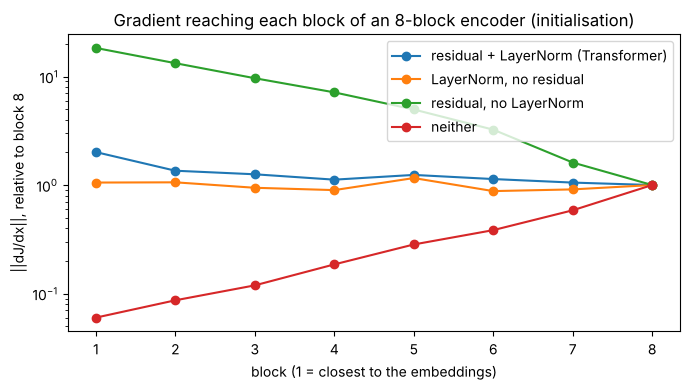

,residual + LayerNorm (Transformer),"LayerNorm, no residual","residual, no LayerNorm",neither
block 1,2,1.1,18,0.06
block 4,1.1,0.9,7.1,0.19


In [15]:
# 6C.3 ||dJ/dx|| at the input of each of 8 blocks, relative to the input of the top block (at initialisation)

rng_depth = np.random.RandomState(0)
depth_ids = rng_depth.choice(train_idx, 64, replace=False)
Xd, Md, _ = batchify(S(depth_ids))
depth_profiles = {}
for name, options in {"residual + LayerNorm (Transformer)": {}, "LayerNorm, no residual": {"residual": False},
                      "residual, no LayerNorm": {"layer_norm": False},
                      "neither": {"residual": False, "layer_norm": False}}.items():
    deep = SequenceClassifier("transformer", "mean", seed=0, layers=8, **options)
    deep.loss_and_grads(Xd, Md, y_all[depth_ids].astype(float))
    norms = np.array(deep.children["encoder"].grad_norms[::-1])      # block 1 (bottom) ... block 8 (top)
    depth_profiles[name] = norms / norms[-1]

plt.figure(figsize=(7, 4))
for name, profile in depth_profiles.items():
    plt.plot(range(1, 9), profile, marker="o", label=name)
plt.yscale("log"); plt.xlabel("block (1 = closest to the embeddings)"); plt.ylabel("||dJ/dx||, relative to block 8")
plt.title("Gradient reaching each block of an 8-block encoder (initialisation)")
plt.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame({name: {"block 1": p[0], "block 4": p[3]} for name, p in depth_profiles.items()})
        .style.format("{:.2g}"))

**Reading 6C.**
- **Every gradient is correct.** For all four classifier variants, every analytic gradient matches its numerical estimate to within about $5\times10^{-7}$ relative error, most entries to $10^{-8}$–$10^{-10}$. This covers the hand-written backward passes of multi-head attention with masking, layer normalization, the feed-forward network, residual connections, both kinds of position vectors, and attention pooling.
- **Residual connections and layer normalization (6C.3).** Without either, only 6% of the gradient at block 8 reaches block 1: in a deep stack the gradient vanishes, as in the RNN of 5G. With residual connections alone it no longer vanishes but *grows* (×18 at block 1), because every block adds its own path to the identity path. Layer normalization alone keeps the scale constant (×1.1). The Transformer combination stays between ×1 and ×2 at every block. The residual path is the lecture's "gradient through the residual connection is 1"; layer normalization keeps the scale of the vectors under control.

## Experiment 6D — Training the Transformer encoder classifier

The default model is one encoder block with $d = 100$ (GloVe size), 4 heads of size 25, a feed-forward layer with 200 hidden units, sinusoidal positions, and attention pooling on top. It is trained like the RNN classifiers (SGD, learning rate 0.1, batch 32, 30 epochs, clipping at 5).

**Ablations on the validation split.** Each lecture component is switched off (or replaced) one at a time. Every variant is trained on the fit part of the training split with 2 seeds and scored on the validation part. The variant with the best mean validation F1 becomes the final model, which is retrained on the full training split with 3 seeds and evaluated once on the test set.

,Validation F1,Validation F1 std,Final train loss,Seconds
Variant,,,,
"default (1 block, 4 heads, sinusoidal positions)",0.956,0.002,0.0031,24
no position representations,0.950,0.014,0.0034,23
learned positions,0.956,0.006,0.0029,22
1 head instead of 4,0.952,0.003,0.0036,21
unscaled dot product,0.950,0.004,0.0027,23
no feed-forward network,0.962,0.000,0.0354,14
no residual connections,0.958,0.014,0.0255,22
no layer normalization,0.957,0.008,0.0036,19
mean pooling instead of attention pooling,0.964,0.005,0.0190,22


Selected on validation: mean pooling instead of attention pooling | {'layers': 1, 'heads': 4, 'd_ff': 200, 'positions': 'sinusoidal'} | pooling: mean


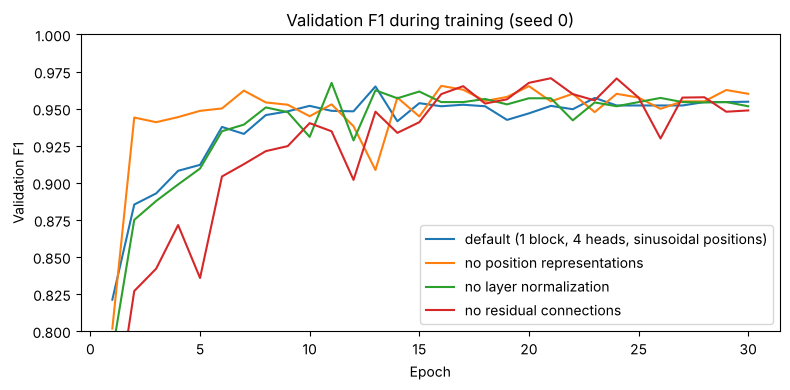

In [16]:
# 6D.1 Ablations on the validation split (2 seeds each)

TF_BASE = dict(layers=1, heads=4, d_ff=200, positions="sinusoidal")
ABLATIONS = {                                           # name: (changes to TF_BASE, pooling)
    "default (1 block, 4 heads, sinusoidal positions)": ({}, "attention"),
    "no position representations": ({"positions": "none"}, "attention"),
    "learned positions": ({"positions": "learned"}, "attention"),
    "1 head instead of 4": ({"heads": 1}, "attention"),
    "unscaled dot product": ({"scaled": False}, "attention"),
    "no feed-forward network": ({"ffn": False}, "attention"),
    "no residual connections": ({"residual": False}, "attention"),
    "no layer normalization": ({"layer_norm": False}, "attention"),
    "mean pooling instead of attention pooling": ({}, "mean"),
    "2 blocks": ({"layers": 2}, "attention"),
}
val_data = (S(val_idx), y_all[val_idx])
ablation_rows, ablation_curves = [], {}
for name, (options, pool) in ABLATIONS.items():
    for seed in [0, 1]:
        start = time.time()
        clf = SequenceClassifier("transformer", pool, seed=seed, **{**TF_BASE, **options}).fit(
            S(fit_idx), y_all[fit_idx].astype(float), val=val_data)
        ablation_curves[(name, seed)] = pd.DataFrame(clf.history)
        ablation_rows.append({"Variant": name, "seed": seed, "Validation F1": clf.history[-1]["validation F1"],
                              "Final train loss": clf.train_loss, "Seconds": time.time() - start})

ablation = pd.DataFrame(ablation_rows).groupby("Variant", sort=False)[
    ["Validation F1", "Final train loss", "Seconds"]].mean()
ablation.insert(1, "Validation F1 std", pd.DataFrame(ablation_rows).groupby("Variant", sort=False)["Validation F1"].std())
display(ablation.style.format({"Validation F1": "{:.3f}", "Validation F1 std": "{:.3f}", "Final train loss": "{:.4f}",
                               "Seconds": "{:.0f}"}).highlight_max(subset=["Validation F1"], color="#d4edda"))

selected_variant = ablation["Validation F1"].idxmax()
TF_OPTIONS, TF_POOL = {**TF_BASE, **ABLATIONS[selected_variant][0]}, ABLATIONS[selected_variant][1]
print("Selected on validation:", selected_variant, "|", TF_OPTIONS, "| pooling:", TF_POOL)

fig, ax = plt.subplots(figsize=(8, 4))
for name in ["default (1 block, 4 heads, sinusoidal positions)", "no position representations",
             "no layer normalization", "no residual connections"]:
    ax.plot(ablation_curves[(name, 0)]["epoch"], ablation_curves[(name, 0)]["validation F1"], label=name)
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation F1"); ax.set_ylim(0.8, 1.0)
ax.set_title("Validation F1 during training (seed 0)"); ax.legend(); plt.tight_layout(); plt.show()

In [17]:
# 6D.2 Final Transformer classifier: selected variant, full training split, 3 seeds, test set

for seed in SEEDS:
    clf = SequenceClassifier("transformer", TF_POOL, seed=seed, **TF_OPTIONS).fit(S(train_idx), y_train.astype(float))
    clf_models[("Transformer encoder", seed)] = clf
    clf_rows.append({"Model": "Transformer encoder", "seed": seed, **binary_metrics(y_test, clf.predict(S(test_idx)))})

clf_results = pd.DataFrame(clf_rows)
clf_summary = clf_results.groupby("Model", sort=False)[["Accuracy", "Precision", "Recall", "F1"]].mean()
clf_summary["F1 std"] = clf_results.groupby("Model", sort=False)["F1"].std()
display(clf_summary.style.format("{:.3f}").highlight_max(subset=["F1"], color="#d4edda"))

,Accuracy,Precision,Recall,F1,F1 std
Model,,,,,
RNN + last,0.927,0.939,0.914,0.926,0.005
RNN + mean,0.949,0.955,0.944,0.949,0.009
RNN + attention,0.945,0.957,0.932,0.944,0.002
Transformer encoder,0.954,0.968,0.939,0.953,0.009


**Reading 6A and 6D.**
- **Attention pooling vs. last state and mean (6A.2).** With the same encoder, training and batches, attention pooling (0.944 ± 0.002) is clearly better than the last state (0.926 ± 0.005) and about level with mean pooling (0.949 ± 0.009). The dark-pattern texts are short (median 6 tokens for manipulative texts), so a plain average already reaches every word; the advantage of a *learned* weighting shows up when a text gets longer (6G.2). In Experiment 5, with randomly drawn batches, the same RNNs scored 0.938 (last) and 0.947 (mean), so only the comparison within this table is controlled.
- **What the RNN attends to (6A.3).** The words with the highest average weight are the dark-pattern cues: *bought, purchased, viewed, added* (activity notifications), *don't, i'd, pay, like* (confirmshaming such as "No thanks, I don't like…"), *demand, left, &lt;num&gt;, hrs* (scarcity and timers). In neutral texts the weight goes to shop navigation: *products, new, collection, view, delivery*. These are the cues TF-IDF found in Experiment 1, but the model learned them without any word-level labels. In the example texts the weight sits on the cue: *hrs* (0.60) in a countdown, *&lt;num&gt;* and *stock* in "only &lt;num&gt; in stock now", *pay* and *price* in "no i'd rather pay full price", *people are* in "&lt;num&gt; people are looking at this product". The weight is not always on one word: in "&lt;num&gt; added to bag in the last &lt;num&gt; hrs" it is spread over *to*, *&lt;num&gt;* and *hrs*. The hidden state at a word also carries the words before it, so a weight on *to* partly stands for "added to".
- **Gradient flow (6A.4).** For the last-state RNN, a quarter of the last word's gradient reaches a word 19 positions earlier (as in 5G.2). With mean pooling every word gets about 5× the last word's gradient at every distance. With attention pooling the gradient a word receives does not depend on its distance but on its attention weight: here earlier words get 22–76× more than the last word, which usually gets little attention. This is the lecture's "shortcut to faraway states".
- **Transformer ablations (6D.1).** All ten variants reach 0.948–0.964 validation F1, and the differences are about the size of the seed-to-seed variation (std up to 0.014). With about 1,500 short training texts, a one-block Transformer does not need any single component to classify well. The components do change how well the model **fits the training data**: without the feed-forward network the final training loss is about 11× higher (0.035 vs. 0.003), without residual connections 8× (0.026), and with mean pooling 6× (0.019). Without residual connections, validation F1 also rises more slowly and is less stable during training (figure). Position representations (none 0.950, sinusoidal 0.956, learned 0.956) and a second block (0.948, twice the training time) do not help.
- **Selected model and test result (6D.2).** The rule "highest mean validation F1" selected **mean pooling** (0.964): one block, 4 heads, sinusoidal positions. On the test set it reaches **0.953 ± 0.009**, the best *discriminative* classifier of the project (RNN + mean 0.949, Naive Bayes 0.949, Experiment 4 network 0.935), but the margin is within one standard deviation.

## Experiment 6E — The Transformer decoder as a language model

A Transformer **decoder** is the encoder with **masked** self-attention: word $i$ may only attend to words $j \le i$, so the model cannot look at the word it has to predict. On top of the last block, $\hat y^{(t)} = \operatorname{softmax}(U h^{(t)} + b_2)$ predicts the next word, exactly like the RNN-LM of Experiment 5C (teacher forcing, cross-entropy, perplexity $= \exp J$).

As in 5E, one LM is trained per class, the number of epochs is chosen on validation perplexity (seed 0), and the final LMs are retrained on the full training split with 3 seeds. The LMs then classify with Bayes' rule:
$\hat y = \arg\max_c \log P_{\text{LM}_c}(\text{text}) + \log P(c)$.

**Optimizer.** Choosing the number of epochs on validation only works if the validation curve is reasonably smooth. 6E.2 trains each LM with the RNN-LM's setting (SGD, learning rate 0.5) and with **Adam** (learning rate 0.001), the optimizer Transformers are normally trained with (Vaswani et al., 2017). Adam keeps running averages of the gradient and of its square and gives every parameter its own step size. The final LMs use Adam; this is the only place where the optimizer differs from Experiments 4–5.

In [18]:
# 6E.1 Transformer decoder language model

def sgd_step(params, lr):
    def step(grads):
        for k in params:
            params[k] -= lr * grads[k]
    return step


def adam_step(params, lr, betas=(0.9, 0.999), eps=1e-8):
    """Adam (Kingma & Ba, 2015): SGD with running averages of g (momentum) and g^2 (per-parameter step size)."""
    m = {k: np.zeros_like(p) for k, p in params.items()}
    v = {k: np.zeros_like(p) for k, p in params.items()}
    t = 0

    def step(grads):
        nonlocal t
        t += 1
        for k in params:
            m[k] = betas[0] * m[k] + (1 - betas[0]) * grads[k]
            v[k] = betas[1] * v[k] + (1 - betas[1]) * grads[k] ** 2
            params[k] -= lr * (m[k] / (1 - betas[0] ** t)) / (np.sqrt(v[k] / (1 - betas[1] ** t)) + eps)
    return step



class TransformerLM(Module):
    """Decoder blocks (causal mask) + y_hat(t) = softmax(U h(t) + b2); same interface as the RNN-LM of Experiment 5."""

    def __init__(self, seed=RANDOM_STATE, **decoder_options):
        super().__init__()
        self.rng = np.random.RandomState(seed)
        decoder = TransformerEncoder(self.rng, causal=True, **decoder_options)
        self.children = {"decoder": decoder}
        self.params = {"U": self.rng.randn(decoder.d, V) * np.sqrt(1.0 / decoder.d), "b2": np.zeros(V)}

    def next_word_probs(self, X, M):
        H = self.children["decoder"].forward(X, M)
        return H, softmax(H @ self.params["U"] + self.params["b2"])           # (B, T, |V|)

    def loss_and_grads(self, X, M, Y):
        H, probs = self.next_word_probs(X, M)
        n_tokens = M.sum()
        p_true = np.take_along_axis(probs, Y[..., None], axis=2)[..., 0]
        loss = -(np.log(p_true + 1e-12) * M).sum() / n_tokens                # mean cross-entropy over predicted words
        dZ = probs                                                          # dJ/dlogits = y_hat - y (one-hot)
        np.put_along_axis(dZ, Y[..., None], p_true[..., None] - 1, axis=2)
        dZ *= (M / n_tokens)[..., None]
        self.grads = {"U": flat(H).T @ flat(dZ), "b2": flat(dZ).sum(axis=0)}
        self.children["decoder"].backward(dZ @ self.params["U"].T)
        return loss

    def fit(self, sequences, epochs=30, optimizer=adam_step, lr=1e-3, batch_size=32, clip=5.0, val_sequences=None):
        params, self.history = self.named_params(), []
        step = optimizer(params, lr)
        for epoch in range(epochs):
            for idx in length_batches(sequences, batch_size, self.rng):
                X, M, Y = batchify([sequences[i] for i in idx], add_bos_eos=True)
                self.loss_and_grads(X, M, Y)
                step(clip_by_global_norm(self.named_grads(), clip)[0])
            if val_sequences is not None:
                self.history.append({"epoch": epoch + 1, "train perplexity": self.perplexity(sequences),
                                     "validation perplexity": self.perplexity(val_sequences)})
        return self

    def sequence_logprobs(self, sequences, batch_size=256):
        """log P(x1 .. xT </s>) for every text (batches of similar length; padding is masked)."""
        order, out = np.argsort([len(s) for s in sequences], kind="stable"), np.empty(len(sequences))
        for start in range(0, len(order), batch_size):
            idx = order[start:start + batch_size]
            X, M, Y = batchify([sequences[i] for i in idx], add_bos_eos=True)
            p_true = np.take_along_axis(self.next_word_probs(X, M)[1], Y[..., None], axis=2)[..., 0]
            out[idx] = (np.log(p_true + 1e-12) * M).sum(axis=1)
        return out

    def perplexity(self, sequences):
        return float(np.exp(-self.sequence_logprobs(sequences).sum() / sum(len(s) + 1 for s in sequences)))

    def sample(self, rng, max_len=25):
        """Generate by repeated sampling; the sampled word becomes the next input."""
        ids = [stoi[BOS]]
        for _ in range(max_len):
            X = np.array([ids])
            p = self.next_word_probs(X, np.ones(X.shape))[1][0, -1].copy()
            p[[stoi[PAD], stoi[BOS]]] = 0
            w = rng.choice(V, p=p / p.sum())
            if w == stoi[EOS]:
                break
            ids.append(w)
        return " ".join(itos[i] for i in ids[1:])


# gradient check, and a check that the decoder cannot see the future
Xl, Ml, Yl = batchify(S(check_ids), add_bos_eos=True)
lm_check = TransformerLM(seed=1, layers=2, heads=4, d_ff=32)
lm_errors, lm_worst = gradient_check(lm_check, lambda m: m.loss_and_grads(Xl, Ml, Yl), np.unique(Xl), rng_check)
display(pd.DataFrame([lm_errors], index=["Transformer LM, 2 blocks, causal mask"]).style.format("{:.1e}"))
report_worst(lm_worst)
X_changed = Xl.copy()
X_changed[:, 4:] = stoi[UNK]                                       # replace every word from position 4 on
p_orig, p_changed = lm_check.next_word_probs(Xl, Ml)[1], lm_check.next_word_probs(X_changed, Ml)[1]
print("Change in the predictions at positions 0-3:", np.abs(p_orig[:, :4] - p_changed[:, :4]).max(),
      "| at positions 4+:", f"{np.abs(p_orig[:, 4:] - p_changed[:, 4:]).max():.2e}")

,LM output U,LM output b2,E,attention Q,attention K,attention V,attention Y,LayerNorm gamma,LayerNorm beta,FFN W1,FFN b1,FFN W2,FFN b2
"Transformer LM, 2 blocks, causal mask",9.4e-08,2.8e-07,6.8e-08,2.2e-05,7.1e-07,2.5e-08,1.2e-08,6.8e-08,1.2e-07,1.2e-07,5.8e-08,1.4e-06,4.3e-08


Largest relative error: 2.2e-05, at an entry with |gradient| = 3.1e-06 (|analytic - numerical| = 1.4e-10)
Change in the predictions at positions 0-3: 0.0 | at positions 4+: 1.21e-02


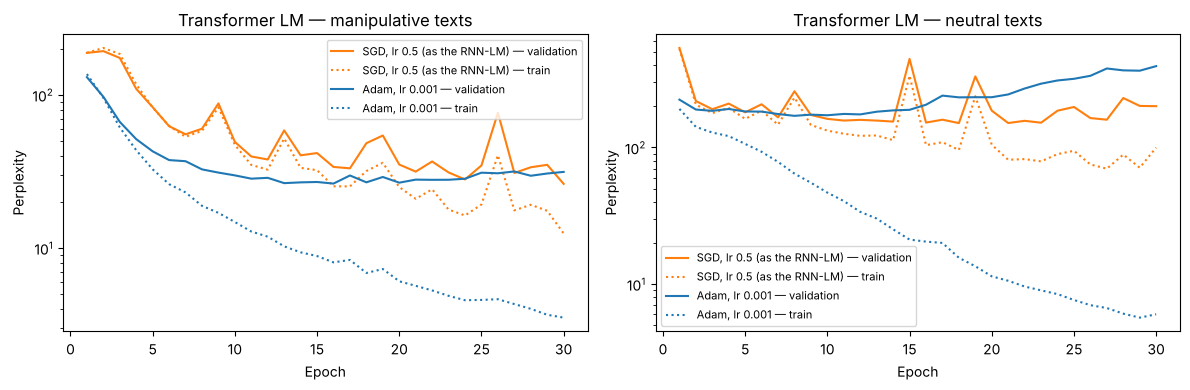

LM,Optimizer,Lowest validation perplexity,at epoch,Largest jump between two epochs
manipulative,"SGD, lr 0.5 (as the RNN-LM)",26.2,30,×2.21
manipulative,"Adam, lr 0.001",26.3,16,×1.13
neutral,"SGD, lr 0.5 (as the RNN-LM)",150.8,18,×2.88
neutral,"Adam, lr 0.001",170.5,8,×1.17


In [19]:
# 6E.2 Optimizer and number of epochs, chosen on validation perplexity (seed 0, fit split)

LM_OPTIONS = dict(layers=1, heads=4, d_ff=200, positions="sinusoidal")
LM_EPOCHS = 30
OPTIMIZERS = {"SGD, lr 0.5 (as the RNN-LM)": (sgd_step, 0.5), "Adam, lr 0.001": (adam_step, 1e-3)}
CLASSES = [(1, "manipulative"), (0, "neutral")]
tf_lm_curves = {}
for c, name in CLASSES:
    for opt_name, (optimizer, lr) in OPTIMIZERS.items():
        selection = TransformerLM(seed=SEEDS[0], **LM_OPTIONS).fit(
            [seqs[i] for i in fit_idx if y_all[i] == c], epochs=LM_EPOCHS, optimizer=optimizer, lr=lr,
            val_sequences=[seqs[i] for i in val_idx if y_all[i] == c])
        tf_lm_curves[(name, opt_name)] = pd.DataFrame(selection.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (c, name) in zip(axes, CLASSES):
    for (opt_name, color) in zip(OPTIMIZERS, ["tab:orange", "tab:blue"]):
        curve = tf_lm_curves[(name, opt_name)]
        ax.plot(curve["epoch"], curve["validation perplexity"], color=color, label=f"{opt_name} — validation")
        ax.plot(curve["epoch"], curve["train perplexity"], color=color, linestyle=":", label=f"{opt_name} — train")
    ax.set_title(f"Transformer LM — {name} texts"); ax.set_xlabel("Epoch"); ax.set_ylabel("Perplexity")
    ax.set_yscale("log"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

lm_selection = pd.DataFrame([{
    "LM": name, "Optimizer": opt_name,
    "Lowest validation perplexity": curve["validation perplexity"].min(),
    "at epoch": int(curve.loc[curve["validation perplexity"].idxmin(), "epoch"]),
    "Largest jump between two epochs": (curve["validation perplexity"] / curve["validation perplexity"].shift()).max(),
} for (name, opt_name), curve in tf_lm_curves.items()])
display(lm_selection.style.format({"Lowest validation perplexity": "{:.1f}", "Largest jump between two epochs": "×{:.2f}"})
        .hide(axis="index"))

In [20]:
# 6E.3 Final LMs: Adam, epochs from the Adam curves, full training split, 3 seeds

adam_curves = {name: tf_lm_curves[(name, "Adam, lr 0.001")] for _, name in CLASSES}
tf_lm_best_epoch = {name: int(curve.loc[curve["validation perplexity"].idxmin(), "epoch"]) for name, curve in adam_curves.items()}
tf_lms_by_seed = {seed: {c: TransformerLM(seed=seed, **LM_OPTIONS).fit([seqs[i] for i in train_idx if y_all[i] == c],
                                                                       epochs=tf_lm_best_epoch[name])
                         for c, name in CLASSES}
                  for seed in SEEDS}
tf_lms = tf_lms_by_seed[SEEDS[0]]      # seed-0 models for the perplexity table and the samples (as in Experiment 5)
print("Epochs:", tf_lm_best_epoch)

Epochs: {'manipulative': 16, 'neutral': 8}


In [21]:
# 6E.4 Test perplexity (same vocabulary and texts as Experiment 5) and LM classification with Bayes' rule

test_by_class = {c: [seqs[i] for i in test_idx if y_all[i] == c] for c in (0, 1)}
perplexity_table = load_table("exp5_perplexity")
tf_ppl = {
    "LM": "Transformer LM (this experiment)",
    "manipulative LM → manipulative test texts": tf_lms[1].perplexity(test_by_class[1]),
    "neutral LM → neutral test texts": tf_lms[0].perplexity(test_by_class[0]),
    "manipulative LM → neutral test texts": tf_lms[1].perplexity(test_by_class[0]),
    "neutral LM → manipulative test texts": tf_lms[0].perplexity(test_by_class[1]),
}
perplexity_table = pd.concat([perplexity_table, pd.DataFrame([tf_ppl])], ignore_index=True)
display(perplexity_table.style.format({c: "{:.1f}" for c in perplexity_table.columns if c != "LM"})
        .highlight_min(subset=["manipulative LM → manipulative test texts", "neutral LM → neutral test texts"],
                       color="#d4edda"))
print("Mean over 3 seeds — manipulative: {:.1f}, neutral: {:.1f}".format(
    np.mean([lms[1].perplexity(test_by_class[1]) for lms in tf_lms_by_seed.values()]),
    np.mean([lms[0].perplexity(test_by_class[0]) for lms in tf_lms_by_seed.values()])))

lm_priors = {c: np.log(np.mean(y_train == c)) for c in (0, 1)}


def lm_scores(lms, sequences):
    """log P(text | manipulative) + log P(manipulative) - [same for neutral]"""
    return (lms[1].sequence_logprobs(sequences) + lm_priors[1]) - (lms[0].sequence_logprobs(sequences) + lm_priors[0])


tf_lm_results = pd.DataFrame([{"seed": seed, **binary_metrics(y_test, (lm_scores(lms, S(test_idx)) > 0).astype(int))}
                              for seed, lms in tf_lms_by_seed.items()])
tf_lm_summary = tf_lm_results.drop(columns="seed").agg(["mean", "std"])
display(tf_lm_summary.style.format("{:.3f}"))

,LM,manipulative LM → manipulative test texts,neutral LM → neutral test texts,manipulative LM → neutral test texts,neutral LM → manipulative test texts
0,unigram,92.6,89.8,176.6,523.7
1,bigram,29.2,101.1,343.5,1174.1
2,trigram,30.6,129.8,404.0,1221.4
3,4-gram,35.5,144.3,439.3,1258.9
4,RNN-LM,20.3,67.3,241.1,615.3
5,Transformer LM (this experiment),20.6,64.9,396.9,1269.7


Mean over 3 seeds — manipulative: 19.8, neutral: 66.4


,Accuracy,Precision,Recall,F1
mean,0.960,0.967,0.953,0.960
std,0.004,0.002,0.011,0.005


In [22]:
# 6E.5 Generating text with the Transformer LMs

rng_gen = np.random.RandomState(0)
for c, name in [(1, "manipulative"), (0, "neutral")]:
    print(f"Transformer LM trained on {name} texts:")
    for _ in range(6):
        print("   ", tf_lms[c].sample(rng_gen))
    print()

Transformer LM trained on manipulative texts:
    limited time offer
    hurry only <num> left in stock
    limited time sale
    <num> <num> people other viewing this people have this
    no i love <unk> free make orders color orders
    no thanks i prefer the last free stuff

Transformer LM trained on neutral texts:
    light john <unk>
    <unk> <unk>
    brown women's
    <unk>
    join <unk>
    <unk>



**Reading 6E.**
- **Optimizer (6E.2).** With SGD and the RNN-LM's learning rate, the validation perplexity jumps by up to ×2.2 (manipulative) and ×2.9 (neutral) from one epoch to the next; with Adam the largest jump is ×1.13 and ×1.17. SGD's lowest point is about the same as Adam's for manipulative texts (26.2 vs. 26.3) and lower for neutral texts (150.8 vs. 170.5), but it is reached on a spiky curve, so the same number of epochs would not reliably give a good model after retraining. With Adam the neutral LM starts to overfit after 8 epochs (validation perplexity rises while training perplexity keeps falling): neutral texts are short and varied, as for the RNN-LM (best epoch 13).
- **Perplexity (6E.4).** The Transformer LM is on par with the RNN-LM: 20.6 vs. 20.3 on manipulative test texts and 64.9 vs. 67.3 on neutral texts (seed 0; mean over 3 seeds 19.8 / 66.4), both far below the best $n$-gram (29.2 / 89.8). On texts of the *other* class its perplexity is much higher than the RNN-LM's (397 vs. 241 and 1,270 vs. 615): the two Transformer LMs are more specialised, i.e. they separate the two "languages" more sharply.
- **Classification.** The Transformer-LM classifier reaches **0.960 ± 0.005** test F1, the highest score in the project, level with the RNN-LM classifier of Experiment 5 (0.958 ± 0.003).
- **Generated text (6E.5).** The manipulative LM reproduces whole templates (*"hurry only &lt;num&gt; left in stock"*, *"limited time offer"*) and confirmshaming (*"no thanks i prefer the last free stuff"*). Neutral samples are short and full of `<unk>`, because neutral texts contain many rare product and brand names.
- **Checks (6E.1).** The LM's gradients are correct; the largest relative error ($2\times10^{-5}$, for $Q$) comes from an entry whose gradient is almost zero ($3\times10^{-6}$), where the finite-difference estimate is limited by rounding: the absolute difference is only $10^{-10}$. The causal mask works: replacing every word from position 4 on leaves the predictions at positions 0–3 exactly unchanged.

## Experiment 6F — What do the attention weights show?

The lecture lists interpretability as a benefit of attention: the attention distribution shows what the model was focusing on. The final Transformer (seed 0) pools its outputs with the selected pooling, so we look inside the self-attention instead: for every word $j$, the **attention it receives** in the first block, $\frac{1}{h\,n}\sum_{\ell}\sum_{i} \alpha^{(\ell)}_{ij}$ (mean over heads and query words; it sums to 1 over the words of a text). 6F.2 shows each head separately for one text.
Attention weights describe where information was *read from*. They are not a full explanation of the decision (the values were transformed by the layers before and after), so we use them as a qualitative check.

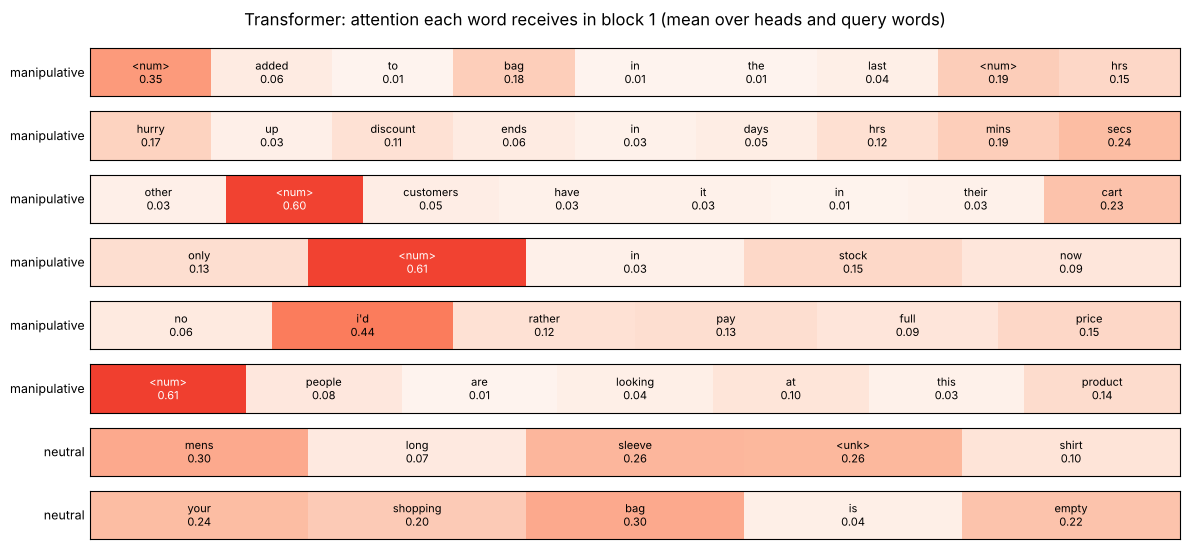

Highest mean attention, manipulative test texts: thanks (0.49), demand (0.45), limited (0.33), purchased (0.32), left (0.31), bought (0.30), <num> (0.29), i'd (0.24), don't (0.24), hurry (0.21), secs (0.17), someone (0.16)
Highest mean attention, neutral test texts:      remotes (0.60), shop (0.40), products (0.40), view (0.35), delivery (0.32), <unk> (0.27), by (0.26), email (0.25), collection (0.24), cookies (0.23), new (0.16), long (0.15)


In [23]:
# 6F.1 Attention each word receives in the first block of the final Transformer (seed 0), on the texts of 6A.3

tf_clf = clf_models[("Transformer encoder", 0)]


def attention_received(seq):
    """Mean over heads and query words of alpha_ij for every key word j (block 1)."""
    tf_clf.forward(*batchify([seq])[:2])
    return tf_clf.children["encoder"].children["block0"].children["attn"].A[0].mean(axis=(0, 1))[:len(seq)]


show_attention([([itos[w] for w in seqs[i]], attention_received(seqs[i]),
                 "manipulative" if y_all[i] else "neutral") for i in example_ids],
               "Transformer: attention each word receives in block 1 (mean over heads and query words)")
print("Highest mean attention, manipulative test texts:", most_attended(attention_received, manip_test_idx))
print("Highest mean attention, neutral test texts:     ", most_attended(attention_received, neutral_test_idx))

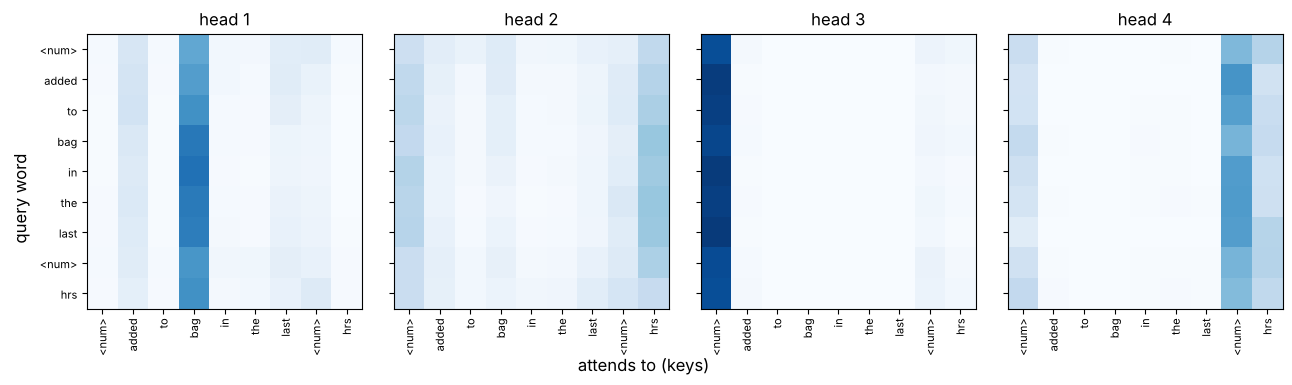

In [24]:
# 6F.2 Self-attention of every head in the first block for one manipulative test text

text_id = max((i for i in example_ids if y_all[i] == 1), key=lambda i: len(seqs[i]))
tf_clf.forward(*batchify([seqs[text_id]])[:2])
A_text = tf_clf.children["encoder"].children["block0"].children["attn"].A[0]     # (heads, T, T)
labels = [itos[w] for w in seqs[text_id]]
fig, axes = plt.subplots(1, A_text.shape[0], figsize=(3.3 * A_text.shape[0], 3.6))
for head, ax in enumerate(np.atleast_1d(axes)):
    ax.imshow(A_text[head], cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90, fontsize=8)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels if head == 0 else [], fontsize=8)
    ax.set_title(f"head {head + 1}")
fig.supxlabel("attends to (keys)"); fig.supylabel("query word")
plt.tight_layout(); plt.show()

**Reading 6F.**
- **Self-attention concentrates on the cue words.** Averaged over heads and query words, the words that receive the most attention in manipulative test texts are *thanks, demand, limited, purchased, left, bought, &lt;num&gt;, i'd, don't, hurry, secs, someone*: the same dark-pattern cues as the RNN's attention pooling (6A.3) and TF-IDF (Experiment 1). In neutral texts attention goes to navigation and product words (*remotes, shop, products, view, delivery*).
- **Numbers matter.** In 4 of the 6 manipulative examples the most-attended word is `<num>` (0.35–0.61): counters such as "&lt;num&gt; people are looking" or "only &lt;num&gt; in stock" carry the scarcity and social-proof signal. In the neutral examples attention is spread more evenly (no word above 0.30).
- **Heads specialise (6F.2).** In "&lt;num&gt; added to bag in the last &lt;num&gt; hrs", head 1 attends mostly to *bag*, head 3 almost only to the first *&lt;num&gt;*, head 4 to the second *&lt;num&gt;* and *hrs*, and head 2 spreads its attention. Each head looks at different words, as in the lecture's multi-head example, although one text is not enough to say what each head "means".

## Experiment 6G — Position representations, long-distance dependencies, and the cost of attention

Four questions from the lecture, asked of models trained on the full training split (3 seeds each):
1. **Which position representation?** The selected Transformer is retrained with each of the lecture's options: none, sinusoidal (fixed, defined for any length) and learned (one vector per position, so it *cannot* represent positions beyond the 41 it was trained with).
2. **Does attention fix the long-distance problem?** We repeat the test of 5G.4: $k$ neutral words from neutral training texts are appended to every manipulative test text, and we count how often the text is still detected.
3. **Do the models use word order?** As in 5F.2, the words of every test text are shuffled. Without position representations, self-attention followed by attention or mean pooling is *exactly* order-invariant (6B.2), so its predictions cannot change.
4. **What does attention cost?** Self-attention compares all pairs of words, so its cost grows *quadratically* with the length $n$; an RNN step is cheap, but the $n$ steps run one after another.

In [25]:
# 6G.1 The selected Transformer with each position representation (full training split, 3 seeds, test set)

POSITION_MODELS = {p: f"Transformer, positions = {p}" for p in ["none", "sinusoidal", "learned"]}
position_rows = []
for positions, name in POSITION_MODELS.items():
    for seed in SEEDS:
        if positions == TF_OPTIONS["positions"]:                  # the final model of 6D.2
            clf = clf_models[("Transformer encoder", seed)]
        else:
            clf = SequenceClassifier("transformer", TF_POOL, seed=seed, **{**TF_OPTIONS, "positions": positions}).fit(
                S(train_idx), y_train.astype(float))
        clf_models[(name, seed)] = clf
        position_rows.append({"Position representation": positions, "seed": seed,
                              "Test F1": f1_score(y_test, clf.predict(S(test_idx)))})
position_results = pd.DataFrame(position_rows).groupby("Position representation", sort=False)["Test F1"].agg(["mean", "std"])
display(position_results.rename(columns={"mean": "Test F1 (mean of 3 seeds)", "std": "std"}).style.format("{:.3f}"))

,Test F1 (mean of 3 seeds),std
Position representation,,
none,0.952,0.009
sinusoidal,0.953,0.009
learned,0.955,0.005


In [26]:
# 6G.2 Long-distance dependency: append k neutral words after every manipulative test text (mean over 3 seeds)

rng_filler = np.random.RandomState(0)
filler_pool = [w for i in rng_filler.permutation(train_idx[y_train == 0]) for w in seqs[i] if w != stoi[UNK]]
manip_test = [seqs[i] for i in manip_test_idx]
probe_models = ["RNN + last", "RNN + mean", "RNN + attention", *POSITION_MODELS.values()]

probe_rows = []
for k in [0, 5, 10, 20, 40]:
    starts = rng_filler.randint(0, len(filler_pool) - k - 1, size=len(manip_test))
    padded = [s + filler_pool[a:a + k] for s, a in zip(manip_test, starts)]
    row = {"neutral words appended": k}
    for name in probe_models:
        try:
            row[name] = np.mean([clf_models[(name, seed)].predict(padded).mean() for seed in SEEDS])
        except ValueError:          # learned positions exist only for positions 0..MAX_LEN
            row[name] = np.nan
    probe_rows.append(row)
long_distance = pd.DataFrame(probe_rows)
display(long_distance.style.format({c: "{:.1%}" for c in probe_models}, na_rep="— (no position vector)")
        .hide(axis="index"))

neutral words appended,RNN + last,RNN + mean,RNN + attention,"Transformer, positions = none","Transformer, positions = sinusoidal","Transformer, positions = learned"
0,91.4%,94.4%,93.2%,94.8%,93.9%,94.1%
5,68.2%,94.9%,93.5%,92.7%,91.2%,— (no position vector)
10,37.9%,92.5%,92.2%,83.9%,88.6%,— (no position vector)
20,22.3%,77.7%,84.7%,69.5%,82.8%,— (no position vector)
40,18.8%,44.6%,73.6%,46.0%,89.8%,— (no position vector)


In [27]:
# 6G.3 Word-order test: shuffle the words inside every test text (mean over 3 seeds)

rng_shuffle = np.random.RandomState(0)
shuffled_test = [list(rng_shuffle.permutation(s)) for s in S(test_idx)]
order_rows = []
for name in probe_models:
    for seed in SEEDS:
        model = clf_models[(name, seed)]
        original, shuffled = model.predict(S(test_idx)), model.predict(shuffled_test)
        order_rows.append({"Model": name, "Test F1 — original order": f1_score(y_test, original),
                           "Test F1 — words shuffled": f1_score(y_test, shuffled),
                           "Predictions changed": np.mean(original != shuffled)})
word_order = pd.DataFrame(order_rows).groupby("Model", sort=False).mean().reset_index()
display(word_order.style.format({"Test F1 — original order": "{:.3f}", "Test F1 — words shuffled": "{:.3f}",
                                 "Predictions changed": "{:.1%}"}).hide(axis="index"))

Model,Test F1 — original order,Test F1 — words shuffled,Predictions changed
RNN + last,0.926,0.929,7.5%
RNN + mean,0.949,0.942,3.7%
RNN + attention,0.944,0.931,5.7%
"Transformer, positions = none",0.952,0.952,0.0%
"Transformer, positions = sinusoidal",0.953,0.939,2.6%
"Transformer, positions = learned",0.955,0.955,1.3%


In [28]:
# 6G.4 Run time of one forward pass for a single text of length n: self-attention layer vs. RNN encoder

rng_time = np.random.RandomState(0)
att_layer = MultiHeadAttention(EMB_DIM, heads=4, rng=rng_time)
rnn_layer = RNNEncoder(rng_time)


def best_time(fn, repeats=5):
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return min(times)


timing_rows = []
for n in [64, 128, 256, 512, 1024, 2048]:
    Xn = rng_time.randn(1, n, EMB_DIM)
    ids, mask = rng_time.randint(4, V, size=(1, n)), np.ones((1, n))
    timing_rows.append({"n": n, "self-attention (ms)": 1000 * best_time(lambda: att_layer.forward(Xn, Xn, mask)),
                        "RNN (ms)": 1000 * best_time(lambda: rnn_layer.forward(ids, mask)),
                        "attention scores computed": 4 * n * n})
timing = pd.DataFrame(timing_rows)
slopes = {c: np.polyfit(np.log(timing["n"][2:]), np.log(timing[c][2:]), 1)[0] for c in ["self-attention (ms)", "RNN (ms)"]}
display(timing.style.format({"self-attention (ms)": "{:.2f}", "RNN (ms)": "{:.2f}", "attention scores computed": "{:,}"})
        .hide(axis="index"))
print("Growth exponent (time ~ n^k, fitted for n >= 256): " + ", ".join(f"{c}: k = {s:.2f}" for c, s in slopes.items()))
print(f"Longest text in our data: {max(len(tokenize_text(t)) for t in main_df['text'])} tokens "
      f"(models see at most {MAX_LEN}).")

n,self-attention (ms),RNN (ms),attention scores computed
64,0.34,1.05,"16,384"
128,1.12,2.03,"65,536"
256,4.02,4.11,"262,144"
512,20.20,9.03,"1,048,576"
1024,82.08,17.77,"4,194,304"
2048,362.32,36.07,"16,777,216"


Growth exponent (time ~ n^k, fitted for n >= 256): self-attention (ms): k = 2.15, RNN (ms): k = 1.04
Longest text in our data: 153 tokens (models see at most 40).


**Reading 6G.**
- **Position representations (6G.1).** On the test set, none (0.952), sinusoidal (0.953) and learned positions (0.955) are within one standard deviation of each other. As in Experiment 5, word order adds little for classification in this templated domain.
- **Long-distance dependencies (6G.2).** The last-state RNN forgets the cue as in 5G.4: detection falls from 91% to 38% after 10 appended neutral words and to 19% after 40. Mean pooling dilutes it: 94% → 78% after 20 words → 45% after 40. **Attention pooling keeps 85% after 20 words and 74% after 40**: the learned query keeps "looking at" the cue, whatever follows. The Transformer without positions ends with mean pooling and behaves like the averaging RNN (70% after 20, 46% after 40). With sinusoidal positions it keeps 83% after 20 words and 90% after 40, but with 40 extra words most texts are longer than any training text (at most 40 tokens), so this is extrapolation to positions never seen in training, which the lecture warns does not reliably work; the detection rate even rises from 20 to 40 words, which is not a meaningful trend. The model with learned positions cannot be evaluated at all: as soon as one text is longer than 41 tokens there is no position vector for it, the lecture's "definitely can't extrapolate".
- **Word order (6G.3).** Without positions, shuffling the words changes **exactly 0%** of the Transformer's predictions, as shown in 6B.2. With sinusoidal or learned positions, 2.6% and 1.3% change, fewer than for the RNNs (3.7–7.5%). Shuffling barely changes F1 for any model: the decision rests on *which* words occur.
- **Cost (6G.4).** The run time of self-attention grows like $n^{2.0}$ and that of the RNN like $n^{1.0}$, the lecture's quadratic cost. Up to about 128–256 tokens self-attention is still faster here, because all pairs are computed in a few matrix products, while the RNN has to run its steps one after another. Our models see at most 40 tokens, so the quadratic cost does not matter for this task.

## Experiment 6H — Comparison with Experiments 1–5

All models are evaluated on the same held-out test set. Neural models: mean over 3 seeds. The external columns appear when the original project dataset is in `data/`.

In [29]:
# 6H.1 Overall comparison

def predictions(model_name, sequences):
    """For the external sets the 3 seeds are combined (mean LM score / majority vote), as in Experiment 5."""
    if model_name == "Transformer-LM classifier":
        return (np.mean([lm_scores(lms, sequences) for lms in tf_lms_by_seed.values()], axis=0) > 0).astype(int)
    return (np.mean([clf_models[(model_name, s)].predict(sequences) for s in SEEDS], axis=0) > 0.5).astype(int)


exp6_models = {
    "RNN + attention pooling": ("RNN + attention", clf_summary.loc["RNN + attention", "F1"]),
    (f"Transformer encoder ({TF_OPTIONS['layers']} block, {TF_OPTIONS['heads']} heads, {TF_OPTIONS['positions']} positions, "
     f"{TF_POOL} pooling)"): ("Transformer encoder", clf_summary.loc["Transformer encoder", "F1"]),
    "Transformer-LM classifier": ("Transformer-LM classifier", tf_lm_summary.loc["mean", "F1"]),
}
hard_neg = (external_synthetic_df["source"] == "synthetic_hard_negative").to_numpy()
exp6_rows = []
for label, (model_name, test_f1) in exp6_models.items():
    row = {"Model": f"Exp. 6 — {label}", "Test F1": test_f1}
    if HAS_EXTERNAL:
        synth_pred = predictions(model_name, synth_seqs)
        y_synth = external_synthetic_df["manipulative"].astype(int).to_numpy()
        row.update({"Real ads F1": f1_score(real_df["manipulative"].astype(int), predictions(model_name, real_seqs)),
                    "Synthetic F1": f1_score(y_synth, synth_pred),
                    "Hard-negative accuracy": accuracy_score(y_synth[hard_neg], synth_pred[hard_neg])})
    exp6_rows.append(row)

overall = pd.concat([load_table("exp5_overall_comparison"), pd.DataFrame(exp6_rows)], ignore_index=True)
if not HAS_EXTERNAL:
    overall = overall[["Model", "Test F1"]]
display(overall.style.format({c: "{:.3f}" for c in overall.columns if c != "Model"}, na_rep="—")
        .highlight_max(subset=["Test F1"], color="#d4edda"))

,Model,Test F1,Real ads F1,Synthetic F1,Hard-negative accuracy
0,Exp. 1 — TF-IDF + logistic regression,0.932,0.468,0.414,0.822
1,Exp. 3 — Word2Vec — project corpus + logistic regression,0.940,0.571,0.498,0.778
2,Exp. 3 — Pretrained GloVe + logistic regression,0.904,0.415,0.404,0.800
3,Exp. 4 — NN (ReLU) — frozen GloVe,0.928,0.427,0.431,0.763
4,Exp. 4 — NN (ReLU) — fine-tuned embeddings,0.935,0.521,0.449,0.715
5,"Exp. 4 — NN (linear, no non-linearity) — frozen GloVe",0.901,0.466,0.448,0.674
6,Exp. 5 — unigram LM (= Naive Bayes),0.949,0.473,0.375,0.867
7,Exp. 5 — bigram LM,0.924,0.621,0.411,0.778
8,Exp. 5 — trigram LM,0.903,0.462,0.401,0.722
9,Exp. 5 — RNN-LM classifier,0.958,0.510,0.412,0.889


In [30]:
# 6H.2 Perplexity as a measure of domain shift (needs the original project dataset)

if HAS_EXTERNAL:
    ext_sets = {"dark-patterns test set": S(test_idx), "our real ads": real_seqs, "our synthetic texts": synth_seqs}
    display(pd.DataFrame([{"LM": f"Transformer LM ({cls})", **{set_name: tf_lms[c].perplexity(set_seqs)
                                                              for set_name, set_seqs in ext_sets.items()}}
                          for c, cls in [(1, "manipulative"), (0, "neutral")]]).style.format({k: "{:.1f}" for k in ext_sets}))
else:
    print("Original project dataset not found in data/ — external check skipped.")

,LM,dark-patterns test set,our real ads,our synthetic texts
0,Transformer LM (manipulative),70.8,135.0,172.4
1,Transformer LM (neutral),367.3,150.8,120.4


**Reading 6H.**

- **Out of domain, Experiment 6 does not change the picture.** On our 57 real ads the three new models reach 0.48–0.54 F1 (RNN + attention 0.52, Transformer encoder 0.48, Transformer-LM 0.54), in the middle of the range of Experiments 1–5 (0.42–0.62). The best transfer still comes from simple models: the bigram LM (0.62) and Word2Vec + logistic regression (0.57). With only 28 manipulative real ads, one ad more or less moves F1 by a few points, so the ranking on this set is noisy.
- **The Transformer encoder transfers worst to the synthetic ad copy.** Its synthetic F1 (0.24) is the lowest of all 15 models, although it still rejects 83% of the hard negatives, so it labels only a small part of the manipulative ad copy as manipulative. The most flexible discriminative model fits the website templates most closely, the same pattern Experiment 4 found for non-linear networks.
- **Hard negatives.** The attention-pooled RNN rejects 84% of them, the Transformer encoder 83% and the Transformer-LM 80%; the RNN-LM (89%) and Naive Bayes (87%) of Experiment 5 remain the best.
- **Domain shift in perplexity (6H.2).** On the dark-patterns test set the two Transformer LMs disagree sharply (perplexity 70.8 under the manipulative LM vs. 367.3 under the neutral LM, over all test texts). On our real ads they are about equally surprised (135.0 vs. 150.8), and on the synthetic texts the *neutral* LM even fits better (120.4 vs. 172.4). Our ads are a third "language", far from both classes the LMs were trained on, so classifying by comparing the two LMs transfers poorly.
- **Why attention does not help here.** Attention made the models robust to *where* a cue appears (6G.2), but the gap to our ads is *which* cues appear: fear, exaggeration and authority do not occur in the dark-patterns training data, and no architecture can learn them from it.

In [31]:
# 6H.3 Save results

save_table(ablation.reset_index(), "exp6_transformer_validation")
save_table(clf_summary.reset_index(), "exp6_classifier_test")
save_table(perplexity_table, "exp6_perplexity")
save_table(position_results.reset_index(), "exp6_position_representations")
save_table(long_distance, "exp6_long_distance")
save_table(word_order, "exp6_word_order")
save_table(overall, "exp6_overall_comparison")
print("Saved to results/.")

Saved to results/.


# Experiment 6 — Summary
| Model (same test split, mean of 3 seeds) | Test F1 |
|---|---|
| RNN classifier, last state | 0.926 ± 0.005 |
| RNN classifier, mean of states | 0.949 ± 0.009 |
| RNN classifier, attention pooling | 0.944 ± 0.002 |
| Transformer encoder (1 block, 4 heads, sinusoidal positions, mean pooling) | 0.953 ± 0.009 |
| **Transformer-LM classifier** (one Transformer decoder LM per class + Bayes' rule) | **0.960 ± 0.005** |
| *Best before:* RNN-LM classifier (Exp. 5) | 0.958 ± 0.003 |

| Test perplexity (lower is better) | Manipulative texts | Neutral texts |
|---|---|---|
| Best $n$-gram (Exp. 5) | 29.2 | 89.8 |
| RNN-LM (Exp. 5) | 20.3 | 67.3 |
| Transformer LM | 20.6 | 64.9 |

| Manipulative test texts still detected after appending 40 neutral words | |
|---|---|
| RNN, last state | 19% |
| RNN, mean pooling / Transformer without positions | 45% / 46% |
| **RNN, attention pooling** | **74%** |
| Transformer, sinusoidal positions | 90%, but extrapolated to positions never seen in training (see 6G) |

| Our own data (3 seeds combined) | Real ads F1 (n=57) | Synthetic F1 (n=370) | Hard-negative accuracy (n=90) |
|---|---|---|---|
| RNN, attention pooling | 0.520 | 0.413 | 0.844 |
| Transformer encoder | 0.480 | 0.244 | 0.833 |
| Transformer-LM classifier | 0.536 | 0.408 | 0.800 |
| *Best of Experiments 1–5* | 0.621 (bigram LM) | 0.498 (Word2Vec + LR) | 0.889 (RNN-LM) |

**What the lecture predicts, and what we observed**

1. *Attention is a learned weighted average that removes the bottleneck and gives a shortcut to faraway states.* Yes: every word gets a direct gradient path (6A.4), and a manipulative cue is still detected after 40 neutral words in 74% of the texts, against 45% with mean pooling and 19% with the last state (6G.2). On the short test texts, attention pooling is about level with mean pooling.
2. *Self-attention, multi-head attention and masking are a few matrix products.* All equations were verified numerically, including the reshaping trick for multiple heads and the causal mask (6B.2).
3. *Dot products grow with the dimension, so they are scaled.* Confirmed: unscaled scores make the softmax almost one-hot and shrink its gradient (6B.3). For our small heads ($d_k = 25$) the unscaled model still trains about as well (validation F1 0.950 vs. 0.956).
4. *Self-attention has no notion of order.* Exactly: without position vectors, shuffled texts get identical predictions (6G.3). Learned positions cannot go beyond the training length. On this data, order adds little anyway.
5. *Residual connections and layer normalization keep deep stacks trainable.* Without both, the gradient vanishes over 8 blocks (6C.3). In our one-block model they mainly change how well the training data is fitted, not validation F1.
6. *A Transformer decoder is a language model.* It matches the RNN-LM in perplexity, and the Transformer-LM classifier gives the best result of the project (6E).
7. *Attention is quadratic in the length.* Measured $n^{2.0}$ vs. $n^{1.0}$ for the RNN (6G.4), irrelevant for texts of at most 40 tokens.
8. *Attention gives some interpretability.* The weights point to the dark-pattern cue words (6A.3, 6F).

**What this means for our research question**
- In-domain, the task is close to saturated: the class-conditional language models stay best (Transformer-LM 0.960 ≈ RNN-LM 0.958), and the Transformer encoder (0.953) is the best discriminative model, but the gains over Experiments 4–5 are within about one standard deviation.
- **Out of domain, attention and Transformers do not help.** On our real ads the new models (0.48–0.54 F1) do not beat the simple bigram LM (0.62) or Word2Vec + logistic regression (0.57), and the Transformer encoder transfers worst to the synthetic ad copy (0.24). Attention makes a model robust to *where* a cue appears, but the gap to our ads is *which* cues appear: fear, exaggeration and authority are missing from the training data (6H).
- Attention weights give a cheap word-level view of *why* a text was flagged, which will be useful for analysing errors on our own ads.

**Limitations.**
- The external sets are small (57 real ads, 28 of them manipulative), so differences of a few F1 points there are within noise.
- Small models (one block, $d = 100$) trained from scratch on about 1,900 texts. The ablation differences are within seed noise (2 seeds per variant on a 376-text validation split); one train/test split, 3 seeds.
- The Transformer LMs were trained with Adam, all other models with SGD. SGD reached a lower validation perplexity for neutral texts, but on an unstable curve.
- Experiment 6 groups texts of similar length into a batch; this changes the RNN results slightly compared with Experiment 5 (last state 0.926 vs. 0.938), so comparisons are made within one experiment.
- Attention weights are not a complete explanation of a decision. LM classifiers also model text length, a known shortcut in this dataset.

**Next steps.** Labeled training examples of fear, exaggeration and authority (e.g. from persuasion-technique datasets), since no model can learn these techniques from the dark-patterns data; pretrained Transformers (encoders such as BERT, fine-tuned on our task) instead of training from scratch; LSTM/GRU cells as the recurrent alternative to attention; a length-controlled comparison of the LM classifiers.